# One-class masked autoencoder (widedeep TabMlp / TabResnet encoder-decoder) at T = 64, 48 and 32

A masking-based autoencoder that follows pytorch-widedeep's self-supervised encoder-decoder pretraining
(`EncoderDecoderTrainer(encoder=TabMlp(...) or TabResnet(...), masked_prob=0.2)`), re-implemented in plain PyTorch,
trained **one-class**: only benign windows fit the weights, benign val windows drive early stopping, the LR schedule and
the alarm thresholds. The benign windows are selected with labels (on-disk benign-only splits at T = 48 / 32; at T = 64
the label file of the train split is read once to keep the benign windows, as in `task/encoder` mode ae); no label
enters the training loss. It runs on exactly the windows of the one-class ConvAE cells (`task/encoder` ae,
`task/autoencoder_benign_t48`, `task/autoencoder_benign_t32`), so its numbers sit next to theirs.

Three label-free scores per window, all over real cells only: **masked_recon** (each real cell hidden exactly once in
five fixed 20 % masks, error of the cell reconstructed while hidden), **full_recon** (nothing hidden) and
**mahalanobis** (distance of z to a Gaussian fitted on the benign train z).

This notebook runs from the repo root and only reads finished runs, one grid of 12 per encoder:
`task/masked_autoencoder/runs/<encoder>/T{64,48,32}-seed{0,1,2,3}/` (`config.run_path`), written by `npm run mae:all`
(TabMlp, `mlp`) and `npm run mae:all:resnet` (TabResnet, `resnet`); it trains nothing and re-scores nothing. The
parameter `ENCODERS` (next cell) lists the encoders to read; an encoder whose grid is not complete on disk is skipped
with a printed note, and every section then covers the encoders present. Sections: 1 input, 2 model, 3 training
record, 4 test results, 5 ROC curves, 6 comparison with the one-class ConvAE, 7 TabMlp vs TabResnet, 8 analysis. Side
experiment, not the thesis TimesNet model.

Parameter: the encoders to read (`mlp` = TabMlp, `resnet` = TabResnet).

In [1]:
ENCODERS = ["mlp", "resnet"]

Setup: repo-root check, package imports, the finished run folders of every encoder present (config, summary, history, test metrics).

In [2]:
import json
from pathlib import Path

assert Path("task/masked_autoencoder/config.py").is_file(), "run this notebook from the repo root"

from task.masked_autoencoder.config import PROTOCOLS, RUNS_DIR, SEEDS, WINDOWS, MAEConfig, is_finished, run_path
from task.masked_autoencoder.data import make_source
from task.masked_autoencoder.evaluate import load_scores
from task.masked_autoencoder.model import MaskedTabularAutoencoder, count_params
from task.masked_autoencoder.plots import PNG_NAME, LossCurvePlot

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import roc_auc_score, roc_curve

pd.set_option("display.width", 200)
SCORES = ("masked_recon", "full_recon", "mahalanobis")
ATTACKS = ("GridSybil", "DataReplay", "DoSRandom", "DoSDisruptive")
ENCODER_NAMES = {"mlp": "TabMlp", "resnet": "TabResnet"}


def run_dir(enc, t, seed):
    return run_path(enc, t, seed)


RUNS, PRESENT = {}, []
for enc in ENCODERS:
    missing = [run_dir(enc, t, s) for t in WINDOWS for s in SEEDS if not is_finished(run_dir(enc, t, s))]
    if missing:
        print(
            f"skipped encoder {enc!r} ({ENCODER_NAMES[enc]}): {len(missing)} of {len(WINDOWS) * len(SEEDS)} runs "
            f"not finished under {run_dir(enc, 64, 0).parent}, e.g. {missing[0].name}"
        )
        continue
    PRESENT.append(enc)
    for t in WINDOWS:
        for seed in SEEDS:
            d = run_dir(enc, t, seed)
            r = {
                name: json.loads((d / f"{name}.json").read_text())
                for name in ("config", "summary", "test_metrics", "env")
            }
            r["history"] = pd.read_json(d / "history.jsonl", lines=True)
            assert r["config"]["window"] == t and r["config"]["seed"] == seed and r["config"]["encoder"] == enc
            assert r["config"]["max_windows"] == 0, "a capped quick-check run"
            assert r["summary"]["label_reads"] == ([] if t != 64 else r["summary"]["label_reads"])
            RUNS[(enc, t, seed)] = r
assert PRESENT, f"no encoder of {ENCODERS} has a finished grid under {RUNS_DIR}"
for enc in PRESENT:
    names = [str(run_dir(enc, t, s).relative_to(RUNS_DIR)) for t in WINDOWS for s in SEEDS]
    print(f"{enc} ({ENCODER_NAMES[enc]}): {len(names)} finished runs under {RUNS_DIR}:", ", ".join(names))

mlp (TabMlp): 12 finished runs under task/masked_autoencoder/runs: mlp/T64-seed0, mlp/T64-seed1, mlp/T64-seed2, mlp/T64-seed3, mlp/T48-seed0, mlp/T48-seed1, mlp/T48-seed2, mlp/T48-seed3, mlp/T32-seed0, mlp/T32-seed1, mlp/T32-seed2, mlp/T32-seed3
resnet (TabResnet): 12 finished runs under task/masked_autoencoder/runs: resnet/T64-seed0, resnet/T64-seed1, resnet/T64-seed2, resnet/T64-seed3, resnet/T48-seed0, resnet/T48-seed1, resnet/T48-seed2, resnet/T48-seed3, resnet/T32-seed0, resnet/T32-seed1, resnet/T32-seed2, resnet/T32-seed3


## 1. Input

Three window sizes, each with the data protocol of its one-class ConvAE sibling (`config.PROTOCOLS`): the encoder input
folder, the sibling's decoded-shard cache, the attack test splits and the early-stopping / LR-schedule settings.

In [3]:
pd.DataFrame(
    {
        t: {
            "data": p.data_dir,
            "sibling (splits, cache, protocol)": p.sibling,
            "attack test splits": ", ".join(p.attack_splits) or "GridSybil inside `test` (mixed)",
            "early-stop patience": p.patience,
            "plateau patience": p.plateau_patience,
            "min_delta (relative)": p.min_delta,
        }
        for t, p in PROTOCOLS.items()
    }
).T

,data,"sibling (splits, cache, protocol)",attack test splits,early-stop patience,plateau patience,min_delta (relative)
64,src/data/encoder_input/benign_gridsybil/T64,task/encoder (mode ae),GridSybil inside `test` (mixed),5,3,0.0
48,src/data/encoder_input/benign_gridsybil/T48_be...,task/autoencoder_benign_t48,test_gridsybil,10,5,0.0001
32,src/data/encoder_input/all/T32_benign,task/autoencoder_benign_t32,"test_gridsybil, test_datareplay, test_dosrando...",10,5,0.0001


Window counts, sender vehicles and tracks per split, from each run's `summary.json` (fit / val) and `test_metrics.json`
(test). They are asserted equal over the four seeds and over the encoders (the seed and the encoder change the weights,
batch order and training masks, not the data). At T = 64 val = 10 % of the benign train sender vehicles
(`VehicleSplit`, split seed 0, the `task/encoder` draw); at T = 48 / 32 val is the on-disk val split.

In [4]:
rows = {}
for t in WINDOWS:
    per_run = []
    for enc in PRESENT:
        for seed in SEEDS:
            s, m = RUNS[(enc, t, seed)]["summary"], RUNS[(enc, t, seed)]["test_metrics"]
            g = m["attacks"]["GridSybil"]
            per_run.append(
                {
                    "train windows (benign)": s["train_windows"],
                    "val windows (benign)": s["val_windows"],
                    "train vehicles": s["train_vehicles"],
                    "val vehicles": s["val_vehicles"],
                    "val tracks": s["val_tracks"],
                    **{f"test {k}": v for k, v in m["windows"].items() if k != "val"},
                    "test vehicles": m["label_checks"]["test_vehicles"],
                    "test vehicles in train / val": m["label_checks"]["test_vehicles_in_train_or_val"],
                    "1-3-row share, benign test": round(g["share_rows_1_3"]["benign"], 3),
                    "1-3-row share, GridSybil test": round(g["share_rows_1_3"]["attack"], 3),
                }
            )
    assert all(p == per_run[0] for p in per_run), f"T{t}: data differ between seeds or encoders"
    rows[f"T = {t}"] = per_run[0]
counts = pd.DataFrame(rows).astype(object).fillna("-")
counts

,T = 64,T = 48,T = 32
train windows (benign),107924.0,112890.0,502773.0
val windows (benign),12149.0,13584.0,65313.0
train vehicles,3263.0,3223.0,4206.0
val vehicles,362.0,402.0,524.0
val tracks,11482.0,12218.0,52108.0
test benign_test,12741.0,13405.0,60142.0
test GridSybil,25685.0,27064.0,28087.0
test vehicles,574.0,574.0,750.0
test vehicles in train / val,0.0,0.0,0.0
"1-3-row share, benign test",0.143,0.138,0.139


The **positive class** differs by T: at T = 64 and 48 the test split holds the benign and GridSybil windows of the
benign + GridSybil folders (GridSybil is the majority, chance PR-AUC ≈ 0.67); at T = 32 the benign test windows come from
all 8 folders and each of the four attacks is tested against the same benign test windows (GridSybil share ≈ 0.32).

## 2. Model

Each window (T × 13, prefix row mask) is flattened to 13 T continuous columns, and the T row-mask values are appended as
T extra input columns: **14 T inputs**. z = 16 for both encoders.

- **mlp (TabMlp)**: encoder [14 T → 64 → 16] (Linear → ReLU → Dropout 0.1 per layer); decoder = the mirrored
  TabMlpDecoder [16 → 64] followed by a plain Linear(64, 13 T).
- **resnet (TabResnet)**: DenseResnet with an input Linear(14 T, 64) + BatchNorm and residual blocks [64, 32, 16]
  (Linear → BatchNorm → LeakyReLU → Dropout 0.1 → Linear → BatchNorm, shortcut Linear + BatchNorm when the width
  changes); decoder = the mirrored TabResnetDecoder [16, 32, 64] + Linear(64, 13 T, bias = False).

During training every real cell is hidden with probability 0.2 (set to 0 in the input, never a padding cell), and the
loss is widedeep's `EncoderDecoderLoss` on the hidden cells only. Linear layers and parameter count per encoder and T
(asserted against the runs' `summary.json`):

In [5]:
param_rows, layer_tables = {}, {}
for enc in PRESENT:
    for t in WINDOWS:
        cfg = MAEConfig.from_dict(RUNS[(enc, t, 0)]["config"])
        model = MaskedTabularAutoencoder(cfg).eval()
        table = []
        hooks = [
            m.register_forward_hook(
                lambda mod, inp, out, name=name: table.append(
                    (name, type(mod).__name__, tuple(out.shape[1:]), sum(p.numel() for p in mod.parameters()))
                )
            )
            for name, m in model.named_modules()
            if isinstance(m, torch.nn.Linear)
        ]
        with torch.no_grad():
            recon, z = model(torch.zeros(2, t, 13), torch.ones(2, t, dtype=torch.bool))
        for h in hooks:
            h.remove()
        layer_tables[(enc, t)] = pd.DataFrame(table, columns=["layer", "type", "output (per window)", "params"])
        params = count_params(model)
        assert all(RUNS[(enc, t, s)]["summary"]["params"] == params for s in SEEDS)
        param_rows[(enc, f"T = {t}")] = {
            "input columns": 14 * t,
            "reconstruction": tuple(recon.shape[1:]),
            "z": z.shape[1],
            "trainable parameters": params,
        }
for enc in PRESENT:
    display(
        layer_tables[(enc, 32)].assign(
            note=f"{ENCODER_NAMES[enc]}, T = 32 shown (Linear layers only); T = 64 / 48 differ only in the 14 T / 13 T widths"
        )
    )
pd.DataFrame(param_rows).T.rename_axis(["encoder", "T"])

,layer,type,output (per window),params,note
0,encoder.mlp.dense_layer_0.0,Linear,"(64,)",28736,"TabMlp, T = 32 shown (Linear layers only); T =..."
1,encoder.mlp.dense_layer_1.0,Linear,"(16,)",1040,"TabMlp, T = 32 shown (Linear layers only); T =..."
2,decoder.0.mlp.dense_layer_0.0,Linear,"(64,)",1088,"TabMlp, T = 32 shown (Linear layers only); T =..."
3,decoder.1,Linear,"(416,)",27040,"TabMlp, T = 32 shown (Linear layers only); T =..."


,layer,type,output (per window),params,note
0,encoder.dense_resnet.lin_inp,Linear,"(64,)",28672,"TabResnet, T = 32 shown (Linear layers only); ..."
1,encoder.dense_resnet.block_0.lin1,Linear,"(32,)",2048,"TabResnet, T = 32 shown (Linear layers only); ..."
2,encoder.dense_resnet.block_0.lin2,Linear,"(32,)",1024,"TabResnet, T = 32 shown (Linear layers only); ..."
3,encoder.dense_resnet.block_0.resize.0,Linear,"(32,)",2048,"TabResnet, T = 32 shown (Linear layers only); ..."
4,encoder.dense_resnet.block_1.lin1,Linear,"(16,)",512,"TabResnet, T = 32 shown (Linear layers only); ..."
5,encoder.dense_resnet.block_1.lin2,Linear,"(16,)",256,"TabResnet, T = 32 shown (Linear layers only); ..."
6,encoder.dense_resnet.block_1.resize.0,Linear,"(16,)",512,"TabResnet, T = 32 shown (Linear layers only); ..."
7,decoder.0.dense_resnet.block_0.lin1,Linear,"(32,)",512,"TabResnet, T = 32 shown (Linear layers only); ..."
8,decoder.0.dense_resnet.block_0.lin2,Linear,"(32,)",1024,"TabResnet, T = 32 shown (Linear layers only); ..."
9,decoder.0.dense_resnet.block_0.resize.0,Linear,"(32,)",512,"TabResnet, T = 32 shown (Linear layers only); ..."


input columns reconstruction   z trainable parameters
encoder T                                                           
mlp     T = 64           896       (64, 13)  16               113616
        T = 48           672       (48, 13)  16                85760
        T = 32           448       (32, 13)  16                57904
resnet  T = 64           896       (64, 13)  16               128224
        T = 48           672       (48, 13)  16               100576
        T = 32           448       (32, 13)  16                72928

For scale: the one-class ConvAEs these runs are compared with have 80,189 / 71,741 / 63,293 parameters at T = 64 / 48 / 32
(package READMEs); the TabMlp (113,616 / 85,760 / 57,904) has more at T = 64 / 48 and fewer at T = 32, nearly all in the
first and last Linear; the TabResnet has 128,224 / 100,576 / 72,928.

**widedeep correspondence** (pytorch_widedeep 1.7.0 wheel, read only; the library is not installed):

| Here | widedeep source |
|---|---|
| `RandomObfuscator` | `models/tabular/self_supervised/_random_obfuscator.py` L14-33 |
| training / eval forward | `models/tabular/self_supervised/encoder_decoder_model.py` L60-70 (eval: mask of ones) |
| mirrored decoder | same file, L96-130 |
| `EncoderDecoderLoss` | `losses.py` L908-970 |
| `dense_layer`, `MLP` | `models/tabular/mlp/_layers.py` L7-22, L52-89 |
| TabMlp / TabMlpDecoder defaults | `models/tabular/mlp/tab_mlp.py` L158-163, L196, L223-301 |
| `BasicBlock`, `DenseResnet` | `models/tabular/resnet/_layers.py` L8-55, L58-90 |
| TabResnet / TabResnetDecoder | `models/tabular/resnet/tab_resnet.py` L189-190, L239, L284-427 |
| optimizer AdamW, train / eval step | `self_supervised_training/_base_encoder_decoder_trainer.py` L59-63; `encoder_decoder_trainer.py` L217-243 |

**Deviations from widedeep** (README):

1. The encoder sees the masked input (`feed_masked_input = True`). widedeep 1.7.0's TabMlp / TabResnet path computes the
   masked input but encodes the clean one (`encoder_decoder_model.py` L64-65); only its TabNet path uses the masked input.
2. The TabMlpDecoder ends in a plain Linear (`linear_mlp_output = True`); widedeep's MLP puts ReLU + dropout after the
   reconstruction layer too, which cannot output negative z-scored values. The TabResnetDecoder already ends in a plain
   Linear.
3. Padding: flattened windows with the row mask as input columns; mask columns never hidden or reconstructed; padding
   cells never hidden, never in the loss, never scored.
4. The loss divides by the batch variance per **feature** (pooled over the batch's real cells), not per column (a late
   time step can have no real cell in a batch); identical to widedeep when T = 1.
5. Batch 256, early stopping and ReduceLROnPlateau (widedeep: batch 32, fixed epochs, no schedule), as in the sibling
   ConvAEs; validation loss = deterministic masked-reconstruction MSE.
6. Small widths with z = 16 (widedeep defaults: TabMlp [200, 100], TabResnet [200, 100, 100]).

## 3. Training record

Per run, from `summary.json` and `history.jsonl`: best epoch, epochs run, stop reason, LR halvings, the best benign val
masked MSE (the early-stopping quantity), the val full MSE and train loss at the best epoch, and the training time.

In [6]:
rec = []
for (enc, t, seed), r in RUNS.items():
    s, h = r["summary"], r["history"]
    b = h.loc[h.epoch == s["best_epoch"]].iloc[0]
    rec.append(
        {
            "encoder": enc,
            "T": t,
            "seed": seed,
            "best epoch": s["best_epoch"],
            "epochs run": s["epochs_run"],
            "stop": s["stop_reason"],
            "LR halvings": len(s["lr_changes"]),
            "first halving after epoch": s["lr_changes"][0]["after_epoch"] if s["lr_changes"] else None,
            "final LR": float(h.lr.iloc[-1]),
            "val masked (best)": s["best_val_loss"],
            "val full (best)": float(b.val_full_mse),
            "train loss (best)": float(b.train_loss),
            "val masked epoch 1": float(h.val_masked_mse.iloc[0]),
            "train min": round(s["train_seconds"] / 60, 1),
            "wall min": round(s["wall_seconds"] / 60, 1),
            "device": s["device"],
            "z dead units": s["z_dead_units_train"],
            "Mahalanobis cond": round(s["mahalanobis"]["cond"], 1),
        }
    )
rec = pd.DataFrame(rec).set_index(["encoder", "T", "seed"])
for r in RUNS.values():  # the summary's best = the history row of the best epoch
    h = r["history"].set_index("epoch")
    assert np.isclose(h.val_masked_mse.loc[r["summary"]["best_epoch"]], r["summary"]["best_val_loss"])
rec.round(4)

best epoch  epochs run            stop  LR halvings  first halving after epoch  final LR  val masked (best)  val full (best)  train loss (best)  val masked epoch 1  train min  \
encoder T  seed                                                                                                                                                                                   
mlp     64 0             63          68  early_stopping            3                         47    0.0001             0.2917           0.2753             0.5124              0.3987        0.9   
           1             41          46  early_stopping            2                         28    0.0002             0.2926           0.2775             0.5138              0.3871        0.7   
           2             46          51  early_stopping            3                         25    0.0001             0.2910           0.2779             0.5097              0.4116        0.7   
           3             68          73  early_stopping            4                         38    0.0001             0.2913           0.2752             0.5093              0.3897        1.0   
        48 0            101         111  early_stopping            5                         47    0.0000             0.3469           0.3306             0.5070              0.4316        1.6   
           1             80          90  early_stopping            5                         25    0.0000             0.3457           0.3282             0.5062              0.4299        1.3   
           2            110         120  early_stopping            5                         54    0.0000             0.3427           0.3230             0.4974              0.4269        1.7   
           3             84          94  early_stopping            3                         42    0.0001             0.3468           0.3299             0.5048              0.4131        1.3   
        32 0             43          53  early_stopping            3                         30    0.0001             0.3248           0.3016             0.4829              0.3572        4.2   
           1             58          68  early_stopping            4                         32    0.0001             0.3192           0.2999             0.4811              0.3550        5.4   
           2             45          55  early_stopping            3                         29    0.0001             0.3267           0.3058             0.4832              0.3568        4.4   
           3             48          58  early_stopping            3                         26    0.0001             0.3259           0.3059             0.4892              0.3559        4.6   
resnet  64 0            161         166  early_stopping            6                         87    0.0000             0.2247           0.2195             0.3715              0.4606        6.6   
           1            129         134  early_stopping            6                         62    0.0000             0.2330           0.2271             0.3816              0.4279        5.3   
           2            174         179  early_stopping            5                        104    0.0000             0.2257           0.2197             0.3675              0.4355        6.9   
           3            164         169  early_stopping            5                        123    0.0000             0.2234           0.2152             0.3644              0.4339        6.6   
        48 0            198         208  early_stopping            7                         88    0.0000             0.2804           0.2779             0.3591              0.4498        9.3   
           1            209         219  early_stopping            7                        124    0.0000             0.2791           0.2779             0.3581              0.4568        8.6   
           2            214         224  early_stopping            5                        144    0.0000            

Loss curves, one figure per encoder present (one row per T, one column per seed), drawn by `task.masked_autoencoder.plots` from
`history.jsonl` + `summary.json`; the same panels are saved as `<run>/loss_curve.png` (`npm run mae:plots`). Blue = the
training loss (`EncoderDecoderLoss`: hidden cells only, divided by the batch variance of each feature, averaged per
window, dropout on); orange = benign val masked-reconstruction MSE (5 fixed masks, pooled over every real cell, dropout
off; early stopping and the LR schedule follow it); green dashed = val full-reconstruction MSE; red = best epoch;
grey dotted = LR halved; purple = LR (right axis). The training loss and the val MSEs are **different quantities**, so
their vertical gap is not a generalisation gap. In short: **training minimises the variance-normalised loss; early
stopping, the LR schedule and all three test scores use the plain MSE on the z-scored features.**

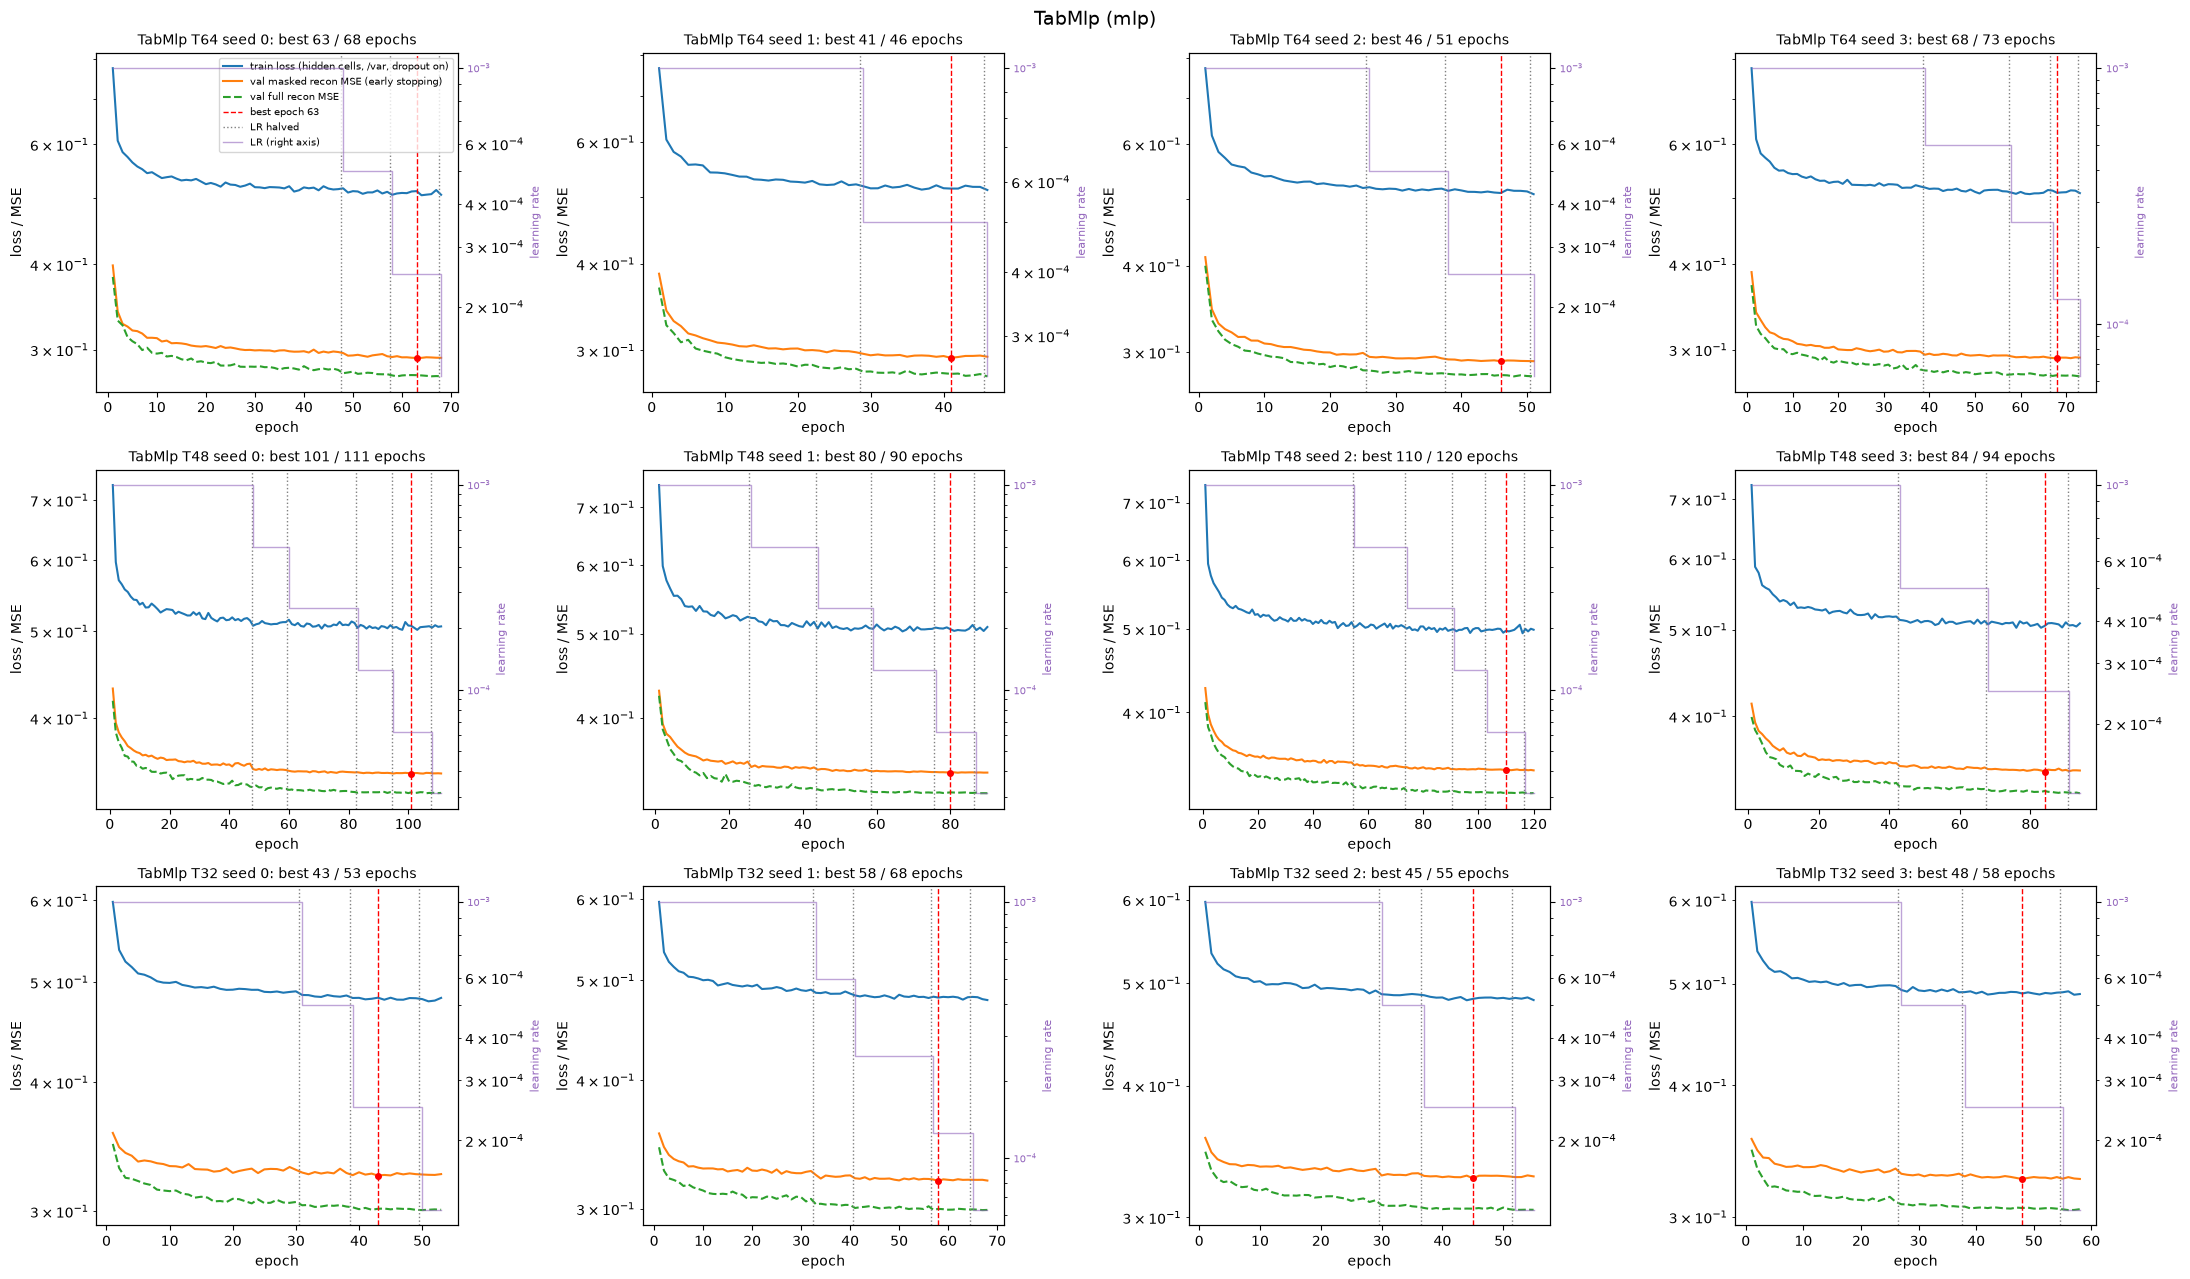

saved PNGs:
  task/masked_autoencoder/runs/mlp/T64-seed0/loss_curve.png
  task/masked_autoencoder/runs/mlp/T64-seed1/loss_curve.png
  task/masked_autoencoder/runs/mlp/T64-seed2/loss_curve.png
  task/masked_autoencoder/runs/mlp/T64-seed3/loss_curve.png
  task/masked_autoencoder/runs/mlp/T48-seed0/loss_curve.png
  task/masked_autoencoder/runs/mlp/T48-seed1/loss_curve.png
  task/masked_autoencoder/runs/mlp/T48-seed2/loss_curve.png
  task/masked_autoencoder/runs/mlp/T48-seed3/loss_curve.png
  task/masked_autoencoder/runs/mlp/T32-seed0/loss_curve.png
  task/masked_autoencoder/runs/mlp/T32-seed1/loss_curve.png
  task/masked_autoencoder/runs/mlp/T32-seed2/loss_curve.png
  task/masked_autoencoder/runs/mlp/T32-seed3/loss_curve.png


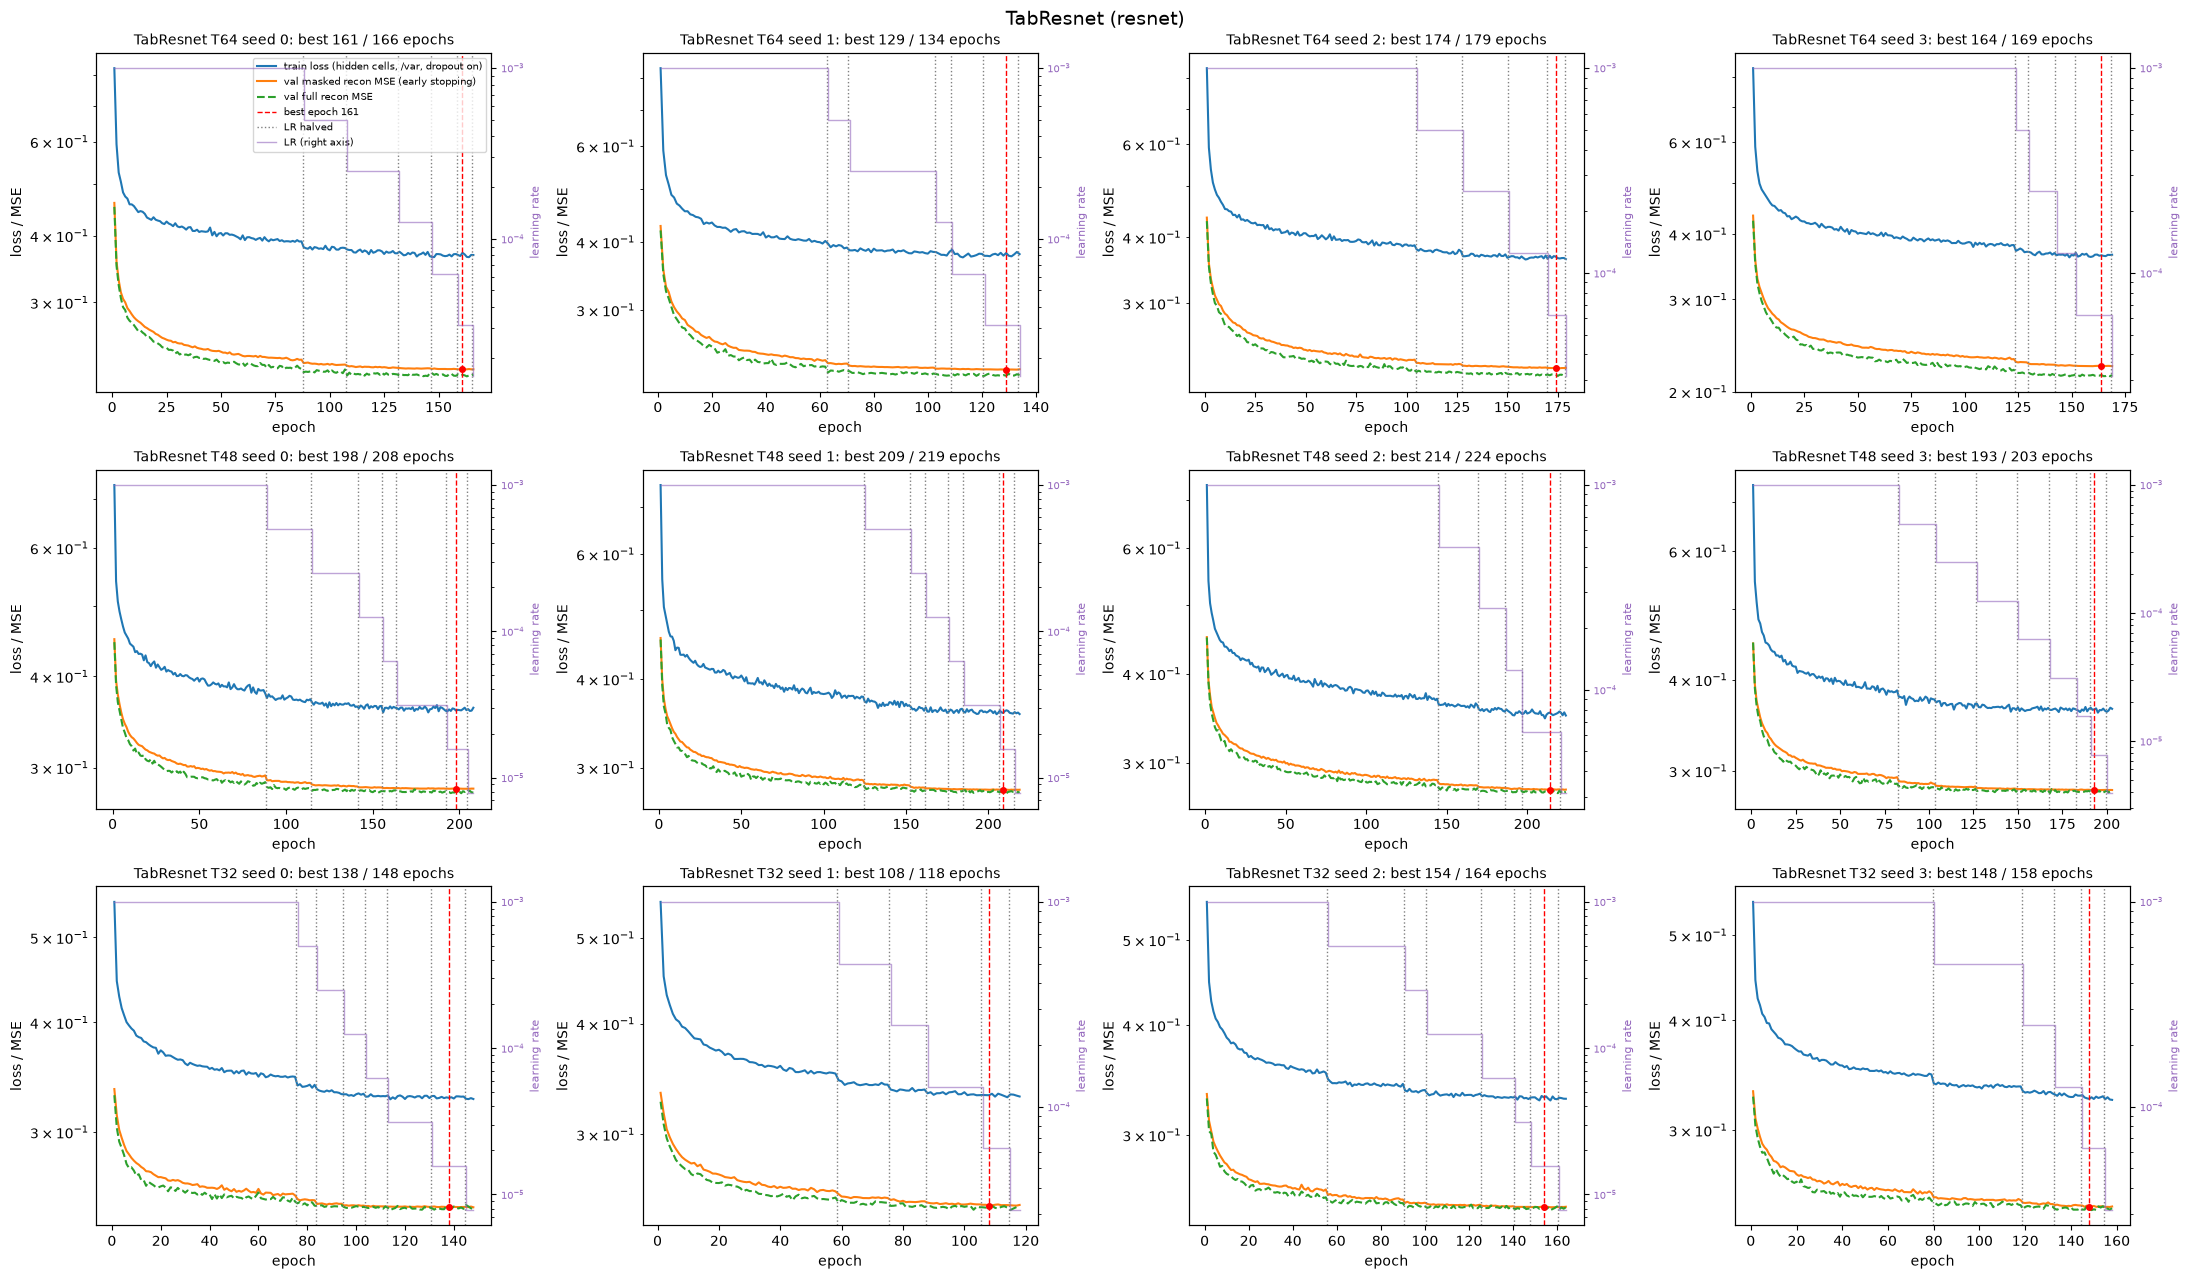

saved PNGs:
  task/masked_autoencoder/runs/resnet/T64-seed0/loss_curve.png
  task/masked_autoencoder/runs/resnet/T64-seed1/loss_curve.png
  task/masked_autoencoder/runs/resnet/T64-seed2/loss_curve.png
  task/masked_autoencoder/runs/resnet/T64-seed3/loss_curve.png
  task/masked_autoencoder/runs/resnet/T48-seed0/loss_curve.png
  task/masked_autoencoder/runs/resnet/T48-seed1/loss_curve.png
  task/masked_autoencoder/runs/resnet/T48-seed2/loss_curve.png
  task/masked_autoencoder/runs/resnet/T48-seed3/loss_curve.png
  task/masked_autoencoder/runs/resnet/T32-seed0/loss_curve.png
  task/masked_autoencoder/runs/resnet/T32-seed1/loss_curve.png
  task/masked_autoencoder/runs/resnet/T32-seed2/loss_curve.png
  task/masked_autoencoder/runs/resnet/T32-seed3/loss_curve.png


In [7]:
for enc in PRESENT:
    fig, axes = plt.subplots(len(WINDOWS), len(SEEDS), figsize=(22, 13))
    for i, t in enumerate(WINDOWS):
        for j, seed in enumerate(SEEDS):
            plot = LossCurvePlot(run_dir(enc, t, seed))
            plot.draw(axes[i, j], legend=(i == 0 and j == 0))
            axes[i, j].set_title(
                f"{ENCODER_NAMES[enc]} T{t} seed {seed}: best {plot.history.best_epoch} / "
                f"{plot.history.summary['epochs_run']} epochs",
                fontsize=10,
            )
            assert (run_dir(enc, t, seed) / PNG_NAME).is_file(), "npm run mae:plots"
    fig.suptitle(f"{ENCODER_NAMES[enc]} ({enc})", fontsize=14)
    fig.tight_layout()
    plt.show()
    print("saved PNGs:", *(str(run_dir(enc, t, s) / PNG_NAME) for t in WINDOWS for s in SEEDS), sep="\n  ")

How the val curve moved: share of the total decrease of the val masked MSE (epoch 1 → best) already reached at epoch 10,
the relative gain from epoch 10 to the best epoch, the relative gain after the first LR halving, and the train / val
ratio at the best epoch (both curves fall together; the ratio says only how the two quantities scale).

In [8]:
shape = []
for (enc, t, seed), r in RUNS.items():
    h, s = r["history"].set_index("epoch"), r["summary"]
    v1, vb, v10 = h.val_masked_mse.iloc[0], s["best_val_loss"], h.val_masked_mse.loc[10]
    first = s["lr_changes"][0]["after_epoch"] if s["lr_changes"] else None
    v_first = h.val_masked_mse.loc[first] if first else np.nan
    shape.append(
        {
            "encoder": enc,
            "T": t,
            "seed": seed,
            "share of decrease by epoch 10": (v1 - v10) / (v1 - vb),
            "rel. gain epoch 10 -> best": (v10 - vb) / v10,
            "rel. gain after first LR halving": (v_first - vb) / v_first,
            "train / val masked at best": h.train_loss.loc[s["best_epoch"]] / vb,
            "val full / val masked at best": h.val_full_mse.loc[s["best_epoch"]] / vb,
            "epochs best -> stop": s["epochs_run"] - s["best_epoch"],
        }
    )
shape = pd.DataFrame(shape).set_index(["encoder", "T", "seed"])
shape.round(3)

share of decrease by epoch 10  rel. gain epoch 10 -> best  rel. gain after first LR halving  train / val masked at best  val full / val masked at best  epochs best -> stop
encoder T  seed                                                                                                                                                                             
mlp     64 0                             0.811                       0.065                             0.020                       1.757                          0.944                    5
           1                             0.846                       0.047                             0.018                       1.756                          0.948                    5
           2                             0.853                       0.057                             0.027                       1.752                          0.955                    5
           3                             0.824                       0.056                             0.023                       1.749                          0.945                    5
        48 0                             0.779                       0.051                             0.025                       1.461                          0.953                   10
           1                             0.808                       0.045                             0.029                       1.464                          0.949                   10
           2                             0.756                       0.057                             0.021                       1.451                          0.942                   10
           3                             0.677                       0.058                             0.021                       1.456                          0.951                   10
        32 0                             0.785                       0.021                             0.013                       1.487                          0.929                   10
           1                             0.749                       0.027                             0.022                       1.507                          0.939                   10
           2                             0.721                       0.025                             0.020                       1.479                          0.936                   10
           3                             0.713                       0.026                             0.023                       1.501                          0.939                   10
resnet  64 0                             0.760                       0.201                             0.041                       1.653                          0.977                    5
           1                             0.721                       0.189                             0.039                       1.638                          0.975                    5
           2                             0.710                       0.212                             0.037                       1.628                          0.973                    5
           3                             0.723                       0.207                             0.032                       1.631                          0.963                    5
        48 0                             0.693                       0.157                             0.042                       1.281                          0.991                   10
           1                             0.687                       0.166                             0.031                       1.283                          0.996                   10
           2                             0.671                       0.173                             0.031                       1.283                          0.993                   10
           3                             0.690  

## 4. Test results

From each run's `test_metrics.json`, written by `evaluate.py` (every val and test window scored and saved before any
label was read; thresholds = benign val p95 / p99 from `summary.json`). Each attack is compared with the benign test
windows of the same test vehicles; the **length-only** reference is the fixed rule score = −real messages per window.
Mean ± sample sd over seeds 0–3 (n = 4).

In [9]:
rows = []
for (enc, t, seed), r in RUNS.items():
    for attack, m in r["test_metrics"]["attacks"].items():
        for name in SCORES:
            w = m["window"][name]
            rows.append(
                {
                    "encoder": enc,
                    "T": t,
                    "seed": seed,
                    "attack": attack,
                    "score": name,
                    "AUROC": w["auroc"],
                    "PR-AUC": w["pr_auc"],
                    "chance": w["chance"],
                    "AUROC 1-3 rows": w["rows_1_3"]["auroc"],
                    "AUROC >= 4 rows": w["rows_ge_4"]["auroc"],
                    "n attack 1-3 rows": w["rows_1_3"]["n_attack"],
                    "n attack >= 4 rows": w["rows_ge_4"]["n_attack"],
                    "n benign >= 4 rows": w["rows_ge_4"]["n_benign"],
                    "recall p95": w["recall_p95"],
                    "benign FPR p95": w["benign_fpr_p95"],
                    "recall p99": w["recall_p99"],
                    "benign FPR p99": w["benign_fpr_p99"],
                    "track max AUROC": m["track"][f"{name}_max"]["auroc"],
                    "track mean AUROC": m["track"][f"{name}_mean"]["auroc"],
                }
            )
        L = m["length_only"]
        rows.append(
            {
                "encoder": enc,
                "T": t,
                "seed": seed,
                "attack": attack,
                "score": "length only",
                "AUROC": L["auroc"],
                "PR-AUC": L["pr_auc"],
                "chance": L["chance"],
            }
        )
res = pd.DataFrame(rows)
SCORE_ORDER = [*SCORES, "length only"]
ENC_SCORE = [(enc, name) for enc in PRESENT for name in SCORE_ORDER]


def mean_sd(df, keys, cols, digits=3):
    # "mean ± sd" strings over seeds (sample sd, ddof 1); asserts 4 seeds per cell.
    g = df.groupby(keys, sort=False)[cols]
    assert (g.size() == len(SEEDS)).all()
    mu, sd = g.mean(), g.std(ddof=1)
    return mu.round(digits).astype(str) + " ± " + sd.round(digits).astype(str), mu, sd


print(
    f"{len(res)} rows: {len(PRESENT)} encoders x {res['T'].nunique()} window sizes x {res.seed.nunique()} seeds "
    "x scores x attacks"
)

192 rows: 2 encoders x 3 window sizes x 4 seeds x scores x attacks


**GridSybil vs benign test**, window AUROC per T (rows = encoder, score; columns = T); PR-AUC with its chance level below.

In [10]:
grid = res[res.attack == "GridSybil"]
txt, mu_auroc, sd_auroc = mean_sd(grid, ["encoder", "score", "T"], ["AUROC"])
gs_table = txt["AUROC"].unstack("T").loc[ENC_SCORE, list(WINDOWS)]
gs_table.columns = [f"T = {t}" for t in WINDOWS]
display(gs_table)
txt_pr, _, _ = mean_sd(grid, ["encoder", "score", "T"], ["PR-AUC", "chance"])
pr = txt_pr["PR-AUC"].unstack("T").loc[ENC_SCORE, list(WINDOWS)]
pr.loc[("", "chance (attack share)"), :] = (
    grid.groupby("T").chance.first().loc[list(WINDOWS)].round(3).astype(str).values
)
pr.columns = [f"T = {t}" for t in WINDOWS]
pr

T = 64         T = 48         T = 32
encoder score                                                    
mlp     masked_recon  0.531 ± 0.002  0.607 ± 0.001  0.657 ± 0.002
        full_recon    0.539 ± 0.003  0.603 ± 0.002   0.65 ± 0.003
        mahalanobis   0.398 ± 0.018  0.403 ± 0.016  0.408 ± 0.017
        length only     0.535 ± 0.0     0.53 ± 0.0    0.559 ± 0.0
resnet  masked_recon  0.595 ± 0.003   0.65 ± 0.002  0.696 ± 0.001
        full_recon    0.605 ± 0.003  0.648 ± 0.001  0.685 ± 0.002
        mahalanobis   0.368 ± 0.009  0.381 ± 0.007  0.378 ± 0.004
        length only     0.535 ± 0.0     0.53 ± 0.0    0.559 ± 0.0

T = 64         T = 48         T = 32
encoder score                                                             
mlp     masked_recon           0.707 ± 0.001  0.773 ± 0.001  0.514 ± 0.001
        full_recon             0.722 ± 0.001  0.772 ± 0.001  0.515 ± 0.001
        mahalanobis            0.634 ± 0.012  0.641 ± 0.009  0.316 ± 0.014
        length only              0.699 ± 0.0    0.697 ± 0.0    0.367 ± 0.0
resnet  masked_recon           0.754 ± 0.004  0.802 ± 0.001  0.566 ± 0.001
        full_recon             0.765 ± 0.003    0.798 ± 0.0  0.553 ± 0.001
        mahalanobis            0.618 ± 0.009  0.641 ± 0.011   0.33 ± 0.013
        length only              0.699 ± 0.0    0.697 ± 0.0    0.367 ± 0.0
        chance (attack share)          0.668          0.669          0.318

Per seed, GridSybil window AUROC (the spread behind the ± above).

In [11]:
grid.pivot_table(index=["encoder", "T", "score"], columns="seed", values="AUROC", sort=False).loc[PRESENT].round(4)

seed                          0       1       2       3
encoder T  score                                       
mlp     64 masked_recon  0.5329  0.5316  0.5285  0.5311
           full_recon    0.5400  0.5407  0.5342  0.5402
           mahalanobis   0.3774  0.4129  0.4128  0.3893
           length only   0.5348  0.5348  0.5348  0.5348
        48 masked_recon  0.6060  0.6073  0.6089  0.6072
           full_recon    0.6006  0.6034  0.6048  0.6014
           mahalanobis   0.4204  0.3846  0.4105  0.3948
           length only   0.5304  0.5304  0.5304  0.5304
        32 masked_recon  0.6556  0.6589  0.6567  0.6552
           full_recon    0.6479  0.6545  0.6511  0.6474
           mahalanobis   0.3957  0.3912  0.4219  0.4241
           length only   0.5586  0.5586  0.5586  0.5586
resnet  64 masked_recon  0.5947  0.5897  0.5959  0.5978
           full_recon    0.6044  0.6010  0.6068  0.6078
           mahalanobis   0.3660  0.3598  0.3649  0.3809
           length only   0.5348  0.5348  0.5348  0.5348
        48 masked_recon  0.6493  0.6508  0.6518  0.6480
           full_recon    0.6472  0.6488  0.6478  0.6466
           mahalanobis   0.3718  0.3875  0.3814  0.3834
           length only   0.5304  0.5304  0.5304  0.5304
        32 masked_recon  0.6954  0.6964  0.6950  0.6978
           full_recon    0.6839  0.6845  0.6840  0.6887
           mahalanobis   0.3757  0.3740  0.3820  0.3806
           length only   0.5586  0.5586  0.5586  0.5586

**T = 32, all four attacks** vs the same benign test windows (window AUROC, mean ± sd over seeds). DataReplay and DoS
windows are mostly 1–3 rows long (F11), so length alone already separates them.

In [12]:
t32 = res[res["T"] == 32]
txt, _, _ = mean_sd(t32, ["encoder", "score", "attack"], ["AUROC"])
t32_table = txt["AUROC"].unstack("attack").loc[ENC_SCORE, list(ATTACKS)]
display(t32_table)
first = RUNS[(PRESENT[0], 32, 0)]["test_metrics"]["attacks"]  # window lengths do not depend on the encoder
share = {a: first[a]["share_rows_1_3"]["attack"] for a in ATTACKS}
share["benign test"] = first["GridSybil"]["share_rows_1_3"]["benign"]
pd.Series(share, name="share of 1-3-row windows").round(3).to_frame().T

attack                    GridSybil     DataReplay      DoSRandom  DoSDisruptive
encoder score                                                                   
mlp     masked_recon  0.657 ± 0.002  0.693 ± 0.003  0.988 ± 0.001  0.851 ± 0.006
        full_recon     0.65 ± 0.003    0.54 ± 0.01  0.976 ± 0.002  0.732 ± 0.007
        mahalanobis   0.408 ± 0.017  0.269 ± 0.036  0.394 ± 0.073  0.222 ± 0.032
        length only     0.559 ± 0.0    0.952 ± 0.0    0.967 ± 0.0    0.967 ± 0.0
resnet  masked_recon  0.696 ± 0.001  0.695 ± 0.008    0.994 ± 0.0  0.859 ± 0.004
        full_recon    0.685 ± 0.002   0.46 ± 0.011  0.964 ± 0.002  0.672 ± 0.009
        mahalanobis   0.378 ± 0.004  0.271 ± 0.023  0.629 ± 0.165  0.281 ± 0.033
        length only     0.559 ± 0.0    0.952 ± 0.0    0.967 ± 0.0    0.967 ± 0.0

,GridSybil,DataReplay,DoSRandom,DoSDisruptive,benign test
share of 1-3-row windows,0.204,0.949,0.997,0.997,0.139


**Short vs long windows**: window AUROC on the windows with 1–3 real rows only and on those with ≥ 4 rows only (both
classes restricted), GridSybil at every T and the four attacks at T = 32.

In [13]:
sub = res[(res.score != "length only") & ((res.attack == "GridSybil") | (res["T"] == 32))].copy()
sub["case"] = "T" + sub["T"].astype(str) + " " + sub["attack"]
txt, _, _ = mean_sd(sub, ["encoder", "case", "score"], ["AUROC", "AUROC 1-3 rows", "AUROC >= 4 rows"])
n_cols = sub.groupby(["encoder", "case", "score"], sort=False)[
    ["n attack 1-3 rows", "n attack >= 4 rows", "n benign >= 4 rows"]
].first()
txt.join(n_cols.astype(int))

AUROC AUROC 1-3 rows AUROC >= 4 rows  n attack 1-3 rows  n attack >= 4 rows  n benign >= 4 rows
encoder case              score                                                                                                                
mlp     T64 GridSybil     masked_recon  0.531 ± 0.002  0.398 ± 0.003    0.55 ± 0.002               4898               20787               10919
                          full_recon    0.539 ± 0.003  0.448 ± 0.007   0.558 ± 0.002               4898               20787               10919
                          mahalanobis   0.398 ± 0.018  0.374 ± 0.031   0.412 ± 0.023               4898               20787               10919
        T48 GridSybil     masked_recon  0.607 ± 0.001  0.499 ± 0.003   0.619 ± 0.001               5003               22061               11559
                          full_recon    0.603 ± 0.002  0.526 ± 0.004   0.618 ± 0.002               5003               22061               11559
                          mahalanobis   0.403 ± 0.016  0.382 ± 0.029   0.414 ± 0.017               5003               22061               11559
        T32 GridSybil     masked_recon  0.657 ± 0.002  0.529 ± 0.001   0.674 ± 0.002               5722               22365               51773
                          full_recon     0.65 ± 0.003  0.563 ± 0.008   0.669 ± 0.003               5722               22365               51773
                          mahalanobis   0.408 ± 0.017  0.373 ± 0.019    0.424 ± 0.02               5722               22365               51773
        T32 DataReplay    masked_recon  0.693 ± 0.003  0.557 ± 0.006   0.359 ± 0.004              72400                3883               51773
                          full_recon      0.54 ± 0.01  0.521 ± 0.009   0.301 ± 0.002              72400                3883               51773
                          mahalanobis   0.269 ± 0.036  0.327 ± 0.014   0.415 ± 0.014              72400                3883               51773
        T32 DoSRandom     masked_recon  0.988 ± 0.001  0.969 ± 0.001       1.0 ± 0.0             199311                 523               51773
                          full_recon    0.976 ± 0.002  0.959 ± 0.003       1.0 ± 0.0             199311                 523               51773
                          mahalanobis   0.394 ± 0.073   0.472 ± 0.11   0.715 ± 0.172             199311                 523               51773
        T32 DoSDisruptive masked_recon  0.851 ± 0.006  0.746 ± 0.007       1.0 ± 0.0             199302                 524               51773
                          full_recon    0.732 ± 0.007  0.704 ± 0.004       1.0 ± 0.0             199302                 524               51773
                          mahalanobis   0.222 ± 0.032  0.288 ± 0.043    0.269 ± 0.05             199302                 524               51773
resnet  T64 GridSybil     masked_recon  0.595 ± 0.003  0.507 ± 0.008   0.604 ± 0.003               4898               20787               10919
                          full_recon    0.605 ± 0.003  0.629 ± 0.006   0.608 ± 0.004               4898               20787               10919
                          mahalanobis   0.368 ± 0.009   0.298 ± 0.02   0.385 ± 0.009               4898               20787               10919
        T48 GridSybil     masked_recon   0.65 ± 0.002  0.596 ± 0.007   0.654 ± 0.001               5003               22061               11559
                          full_recon    0.648 ± 0.001  0.641 ± 0.003   0.654 ± 0.001               5003               22061               11559
                          mahalanobis   0.381 ± 0.007   0.318 ± 0.01    0.398 ± 0.01               5003               22061               11559
        T32 GridSybil     masked_recon  0.696 ± 0.001  0.619 ± 0.004   0.706 ± 0.001               5722               22365               51773
                          full_recon    0.685 ± 0.002  0.664 ± 0.009   0.699 ± 0.002               5722               22365               51773
                

The window counts are the same in every seed. At T = 32 the ≥ 4-row subsets of DoSRandom and DoSDisruptive hold only a
few hundred attack windows (column `n attack >= 4 rows`), so an AUROC near 1.000 there rests on a small sample.

**Alarms at the benign val thresholds**: attack recall and benign-test FPR at val p95 and p99 (window level). On benign
data from the val distribution the FPR would be 0.05 / 0.01.

In [14]:
txt, _, _ = mean_sd(sub, ["encoder", "case", "score"], ["recall p95", "benign FPR p95", "recall p99", "benign FPR p99"])
txt

recall p95 benign FPR p95     recall p99 benign FPR p99
encoder case              score                                                                   
mlp     T64 GridSybil     masked_recon  0.093 ± 0.001  0.048 ± 0.001  0.027 ± 0.001     0.01 ± 0.0
                          full_recon    0.112 ± 0.001  0.047 ± 0.001  0.051 ± 0.001  0.011 ± 0.001
                          mahalanobis   0.065 ± 0.006  0.055 ± 0.004  0.038 ± 0.005  0.011 ± 0.001
        T48 GridSybil     masked_recon  0.172 ± 0.001  0.045 ± 0.001    0.076 ± 0.0    0.008 ± 0.0
                          full_recon    0.174 ± 0.001  0.045 ± 0.001  0.084 ± 0.001    0.009 ± 0.0
                          mahalanobis    0.072 ± 0.01  0.052 ± 0.003  0.038 ± 0.007  0.009 ± 0.001
        T32 GridSybil     masked_recon     0.21 ± 0.0    0.052 ± 0.0  0.087 ± 0.002    0.009 ± 0.0
                          full_recon    0.214 ± 0.001    0.051 ± 0.0  0.094 ± 0.002    0.008 ± 0.0
                          mahalanobis    0.077 ± 0.01  0.053 ± 0.002  0.048 ± 0.006  0.011 ± 0.001
        T32 DataReplay    masked_recon  0.137 ± 0.001    0.052 ± 0.0  0.055 ± 0.002    0.009 ± 0.0
                          full_recon    0.091 ± 0.004    0.051 ± 0.0  0.034 ± 0.001    0.008 ± 0.0
                          mahalanobis   0.009 ± 0.002  0.053 ± 0.002    0.002 ± 0.0  0.011 ± 0.001
        T32 DoSRandom     masked_recon  0.942 ± 0.003    0.052 ± 0.0  0.807 ± 0.006    0.009 ± 0.0
                          full_recon    0.884 ± 0.012    0.051 ± 0.0  0.691 ± 0.015    0.008 ± 0.0
                          mahalanobis    0.02 ± 0.021  0.053 ± 0.002  0.002 ± 0.003  0.011 ± 0.001
        T32 DoSDisruptive masked_recon  0.448 ± 0.011    0.052 ± 0.0  0.318 ± 0.011    0.009 ± 0.0
                          full_recon    0.367 ± 0.005    0.051 ± 0.0  0.252 ± 0.006    0.008 ± 0.0
                          mahalanobis   0.002 ± 0.001  0.053 ± 0.002      0.0 ± 0.0  0.011 ± 0.001
resnet  T64 GridSybil     masked_recon   0.14 ± 0.007   0.05 ± 0.001  0.056 ± 0.005    0.009 ± 0.0
                          full_recon    0.155 ± 0.003  0.052 ± 0.001  0.078 ± 0.003     0.01 ± 0.0
                          mahalanobis   0.059 ± 0.009  0.054 ± 0.004  0.025 ± 0.011  0.013 ± 0.003
        T48 GridSybil     masked_recon  0.208 ± 0.002  0.046 ± 0.001   0.11 ± 0.002    0.009 ± 0.0
                          full_recon    0.195 ± 0.001    0.045 ± 0.0  0.101 ± 0.002    0.009 ± 0.0
                          mahalanobis   0.083 ± 0.011  0.052 ± 0.001  0.052 ± 0.015  0.011 ± 0.001
        T32 GridSybil     masked_recon   0.25 ± 0.003  0.051 ± 0.001  0.127 ± 0.001    0.009 ± 0.0
                          full_recon    0.233 ± 0.001    0.049 ± 0.0  0.116 ± 0.002    0.008 ± 0.0
                          mahalanobis     0.1 ± 0.012  0.049 ± 0.003  0.073 ± 0.014   0.01 ± 0.001
        T32 DataReplay    masked_recon  0.142 ± 0.003  0.051 ± 0.001  0.057 ± 0.002    0.009 ± 0.0
                          full_recon    0.053 ± 0.005    0.049 ± 0.0  0.026 ± 0.002    0.008 ± 0.0
                          mahalanobis   0.012 ± 0.007  0.049 ± 0.003  0.003 ± 0.004   0.01 ± 0.001
        T32 DoSRandom     masked_recon  0.971 ± 0.002  0.051 ± 0.001  0.883 ± 0.007    0.009 ± 0.0
                          full_recon    0.825 ± 0.013    0.049 ± 0.0  0.605 ± 0.021    0.008 ± 0.0
                          mahalanobis   0.193 ± 0.196  0.049 ± 0.003  0.093 ± 0.136   0.01 ± 0.001
        T32 DoSDisruptive masked_recon  0.452 ± 0.005  0.051 ± 0.001   0.32 ± 0.007    0.009 ± 0.0
                          full_recon     0.311 ± 0.01    0.049 ± 0.0  0.218 ± 0.007    0.008 ± 0.0
                          mahalanobis   0.032 ± 0.033  0.049 ± 0.003  0.016 ± 0.021   0.01 ± 0.001

Per track (max / mean of a link's windows), window AUROC for comparison.

In [15]:
txt, _, _ = mean_sd(sub, ["encoder", "case", "score"], ["AUROC", "track max AUROC", "track mean AUROC"])
txt

AUROC track max AUROC track mean AUROC
encoder case              score                                                       
mlp     T64 GridSybil     masked_recon  0.531 ± 0.002   0.521 ± 0.002    0.522 ± 0.002
                          full_recon    0.539 ± 0.003   0.529 ± 0.003     0.53 ± 0.003
                          mahalanobis   0.398 ± 0.018   0.385 ± 0.017    0.385 ± 0.017
        T48 GridSybil     masked_recon  0.607 ± 0.001   0.594 ± 0.001    0.595 ± 0.001
                          full_recon    0.603 ± 0.002   0.589 ± 0.002     0.59 ± 0.002
                          mahalanobis   0.403 ± 0.016   0.385 ± 0.016    0.383 ± 0.017
        T32 GridSybil     masked_recon  0.657 ± 0.002    0.63 ± 0.002    0.638 ± 0.002
                          full_recon     0.65 ± 0.003   0.623 ± 0.004     0.63 ± 0.004
                          mahalanobis   0.408 ± 0.017    0.382 ± 0.02     0.382 ± 0.02
        T32 DataReplay    masked_recon  0.693 ± 0.003   0.651 ± 0.003    0.673 ± 0.003
                          full_recon      0.54 ± 0.01    0.495 ± 0.01     0.517 ± 0.01
                          mahalanobis   0.269 ± 0.036   0.247 ± 0.029    0.262 ± 0.032
        T32 DoSRandom     masked_recon  0.988 ± 0.001   0.985 ± 0.001    0.987 ± 0.001
                          full_recon    0.976 ± 0.002   0.971 ± 0.003    0.974 ± 0.003
                          mahalanobis   0.394 ± 0.073   0.368 ± 0.077     0.391 ± 0.08
        T32 DoSDisruptive masked_recon  0.851 ± 0.006   0.825 ± 0.006     0.84 ± 0.006
                          full_recon    0.732 ± 0.007   0.701 ± 0.007    0.717 ± 0.007
                          mahalanobis   0.222 ± 0.032     0.2 ± 0.026    0.214 ± 0.028
resnet  T64 GridSybil     masked_recon  0.595 ± 0.003   0.586 ± 0.004    0.587 ± 0.004
                          full_recon    0.605 ± 0.003   0.596 ± 0.003    0.597 ± 0.003
                          mahalanobis   0.368 ± 0.009   0.355 ± 0.009    0.352 ± 0.009
        T48 GridSybil     masked_recon   0.65 ± 0.002   0.639 ± 0.002     0.64 ± 0.002
                          full_recon    0.648 ± 0.001   0.636 ± 0.001    0.637 ± 0.001
                          mahalanobis   0.381 ± 0.007   0.358 ± 0.005    0.353 ± 0.005
        T32 GridSybil     masked_recon  0.696 ± 0.001   0.674 ± 0.001    0.681 ± 0.001
                          full_recon    0.685 ± 0.002    0.66 ± 0.003    0.667 ± 0.003
                          mahalanobis   0.378 ± 0.004   0.347 ± 0.005    0.344 ± 0.004
        T32 DataReplay    masked_recon  0.695 ± 0.008   0.655 ± 0.009    0.675 ± 0.009
                          full_recon     0.46 ± 0.011    0.416 ± 0.01     0.435 ± 0.01
                          mahalanobis   0.271 ± 0.023   0.264 ± 0.022    0.279 ± 0.024
        T32 DoSRandom     masked_recon    0.994 ± 0.0     0.992 ± 0.0      0.993 ± 0.0
                          full_recon    0.964 ± 0.002   0.957 ± 0.003    0.962 ± 0.002
                          mahalanobis   0.629 ± 0.165   0.623 ± 0.167    0.652 ± 0.166
        T32 DoSDisruptive masked_recon  0.859 ± 0.004   0.835 ± 0.004    0.849 ± 0.004
                          full_recon    0.672 ± 0.009   0.639 ± 0.009    0.654 ± 0.009
                          mahalanobis   0.281 ± 0.033   0.275 ± 0.033    0.289 ± 0.034

## 5. ROC curves from the saved score files

ROC curves are recomputed from `scores/<split>.npz` (written before labels were read). At T = 48 / 32 the class is the
split (benign `test` vs `test_<attack>`); at T = 64 the `test` split is mixed, so its label file is read here through the
package's `T64Source` (the read is logged on that source object) and aligned by window id. Each recomputed AUROC is
asserted equal to `test_metrics.json`.

In [16]:
def roc_data(enc, t, seed, attack):
    # (labels, {score: values}, n_messages) for one attack vs benign test, from the score files only.
    folder = run_dir(enc, t, seed) / "scores"
    if t == 64:
        test = load_scores(folder, "test")
        y = (T64_CODES != 0).astype(int)
        return y, test.scores, test.n_messages
    b = load_scores(folder, "test")
    a = load_scores(folder, f"test_{attack.lower()}")
    y = np.r_[np.zeros(len(b), int), np.ones(len(a), int)]
    return y, {k: np.r_[b.scores[k], a.scores[k]] for k in SCORES}, np.r_[b.n_messages, a.n_messages]


src64 = make_source(MAEConfig.from_dict(RUNS[(PRESENT[0], 64, 0)]["config"]))
T64_CODES = src64.labels("test", "masked_autoencoder notebook: ROC curves from the saved T64 score files")
ids64 = src64.load("test").ids
for enc in PRESENT:
    for seed in SEEDS:
        assert np.array_equal(load_scores(run_dir(enc, 64, seed) / "scores", "test").ids, ids64), "T64 ids not aligned"
assert set(np.unique(T64_CODES)) <= {0, 16}
print(
    "T64 test labels read:", src64.label_reads, "| windows", len(T64_CODES), "GridSybil", int((T64_CODES == 16).sum())
)

checked = 0
for (enc, t, seed), r in RUNS.items():
    for attack in r["test_metrics"]["attacks"]:
        y, s, n = roc_data(enc, t, seed, attack)
        for name in SCORES:
            ref = r["test_metrics"]["attacks"][attack]["window"][name]["auroc"]
            assert abs(roc_auc_score(y, s[name]) - ref) < 1e-6, (enc, t, seed, attack, name)
            checked += 1
        assert (
            abs(roc_auc_score(y, -n.astype(float)) - r["test_metrics"]["attacks"][attack]["length_only"]["auroc"])
            < 1e-6
        )
print(f"{checked} AUROCs recomputed from the score files = test_metrics.json")

T64 test labels read: ['test: masked_autoencoder notebook: ROC curves from the saved T64 score files'] | windows 38426 GridSybil 25685


144 AUROCs recomputed from the score files = test_metrics.json


GridSybil vs benign test per T (one row per encoder): the three scores and the length-only rule, all four seeds (thin
lines; the AUROC in the legend is the mean over seeds).

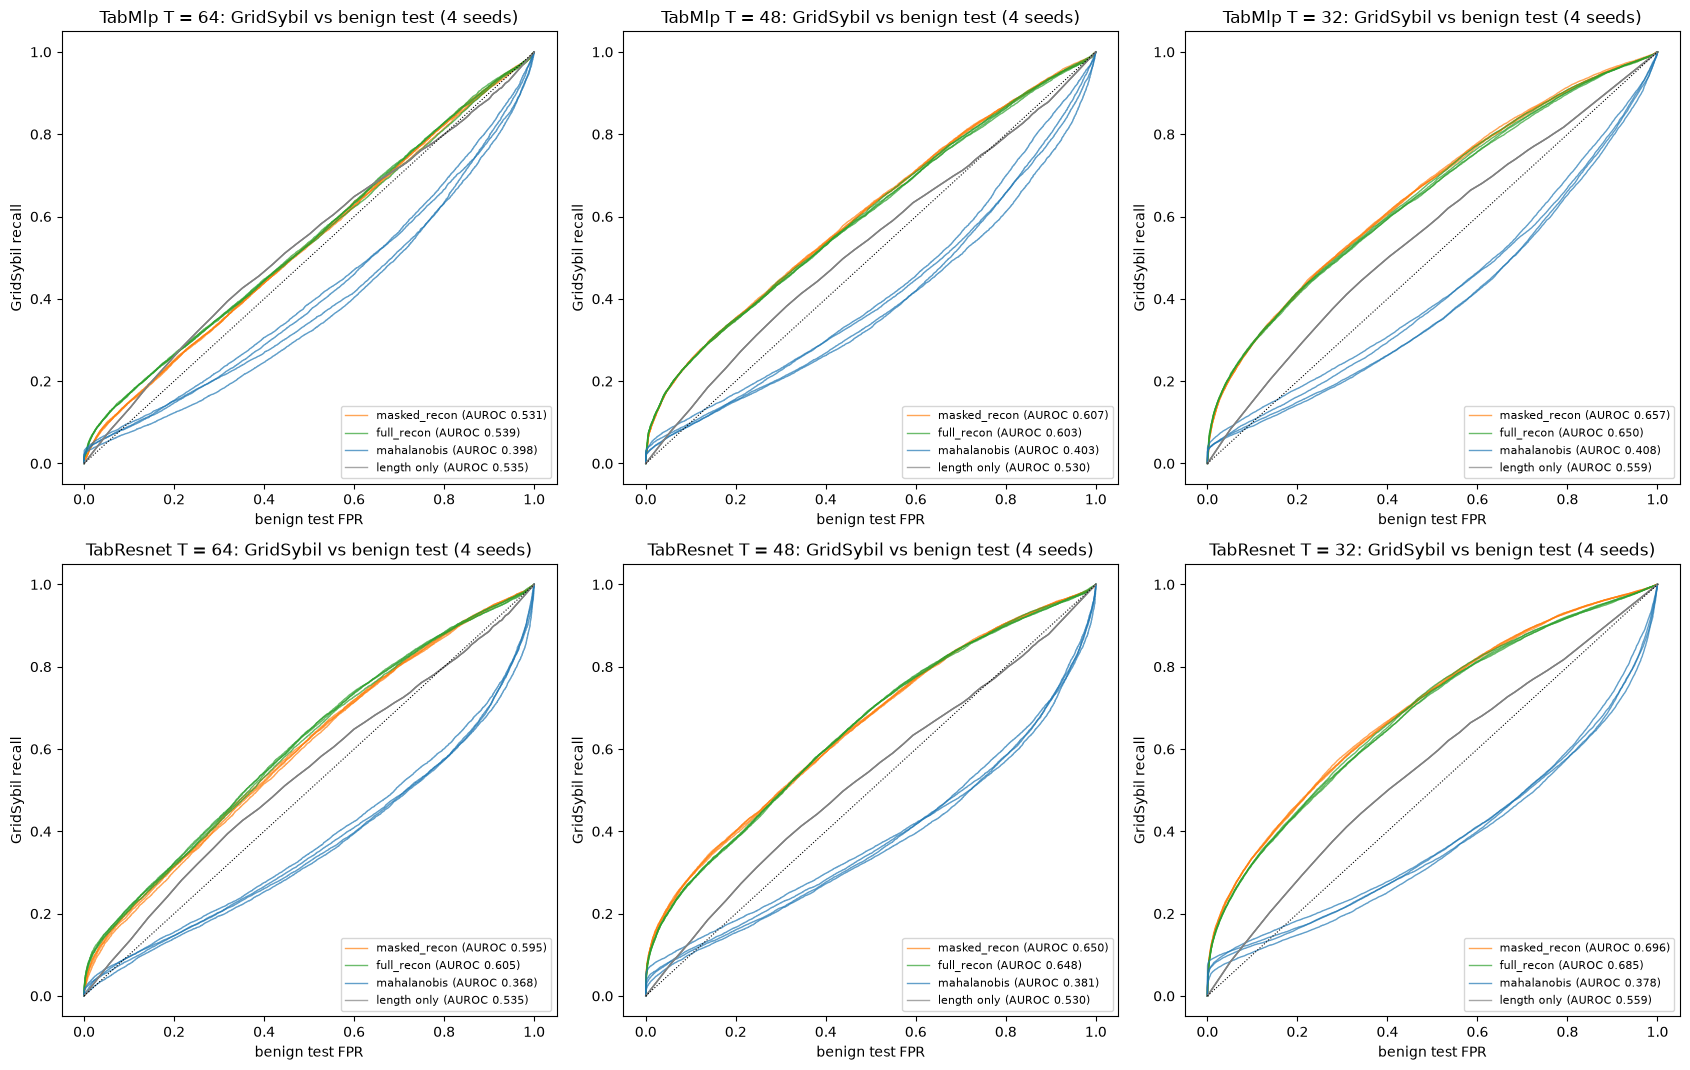

In [17]:
colors = {"masked_recon": "tab:orange", "full_recon": "tab:green", "mahalanobis": "tab:blue", "length only": "grey"}
fig, axes = plt.subplots(len(PRESENT), 3, figsize=(17, 5.4 * len(PRESENT)), squeeze=False)
for row, enc in enumerate(PRESENT):
    for ax, t in zip(axes[row], WINDOWS):
        for name in SCORE_ORDER:
            aucs = []
            for k, seed in enumerate(SEEDS):
                y, s, n = roc_data(enc, t, seed, "GridSybil")
                v = -n.astype(float) if name == "length only" else s[name]
                fpr, tpr, _ = roc_curve(y, v)
                aucs.append(roc_auc_score(y, v))
                ax.plot(
                    fpr,
                    tpr,
                    color=colors[name],
                    lw=1,
                    alpha=0.7,
                    label=f"{name} (AUROC {np.mean(aucs if k else [aucs[0]]):.3f})" if k == len(SEEDS) - 1 else None,
                )
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set_title(f"{ENCODER_NAMES[enc]} T = {t}: GridSybil vs benign test (4 seeds)")
        ax.set_xlabel("benign test FPR")
        ax.set_ylabel("GridSybil recall")
        ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

T = 32, the four attacks vs benign test (seed 0, three scores + length only; one row per encoder).

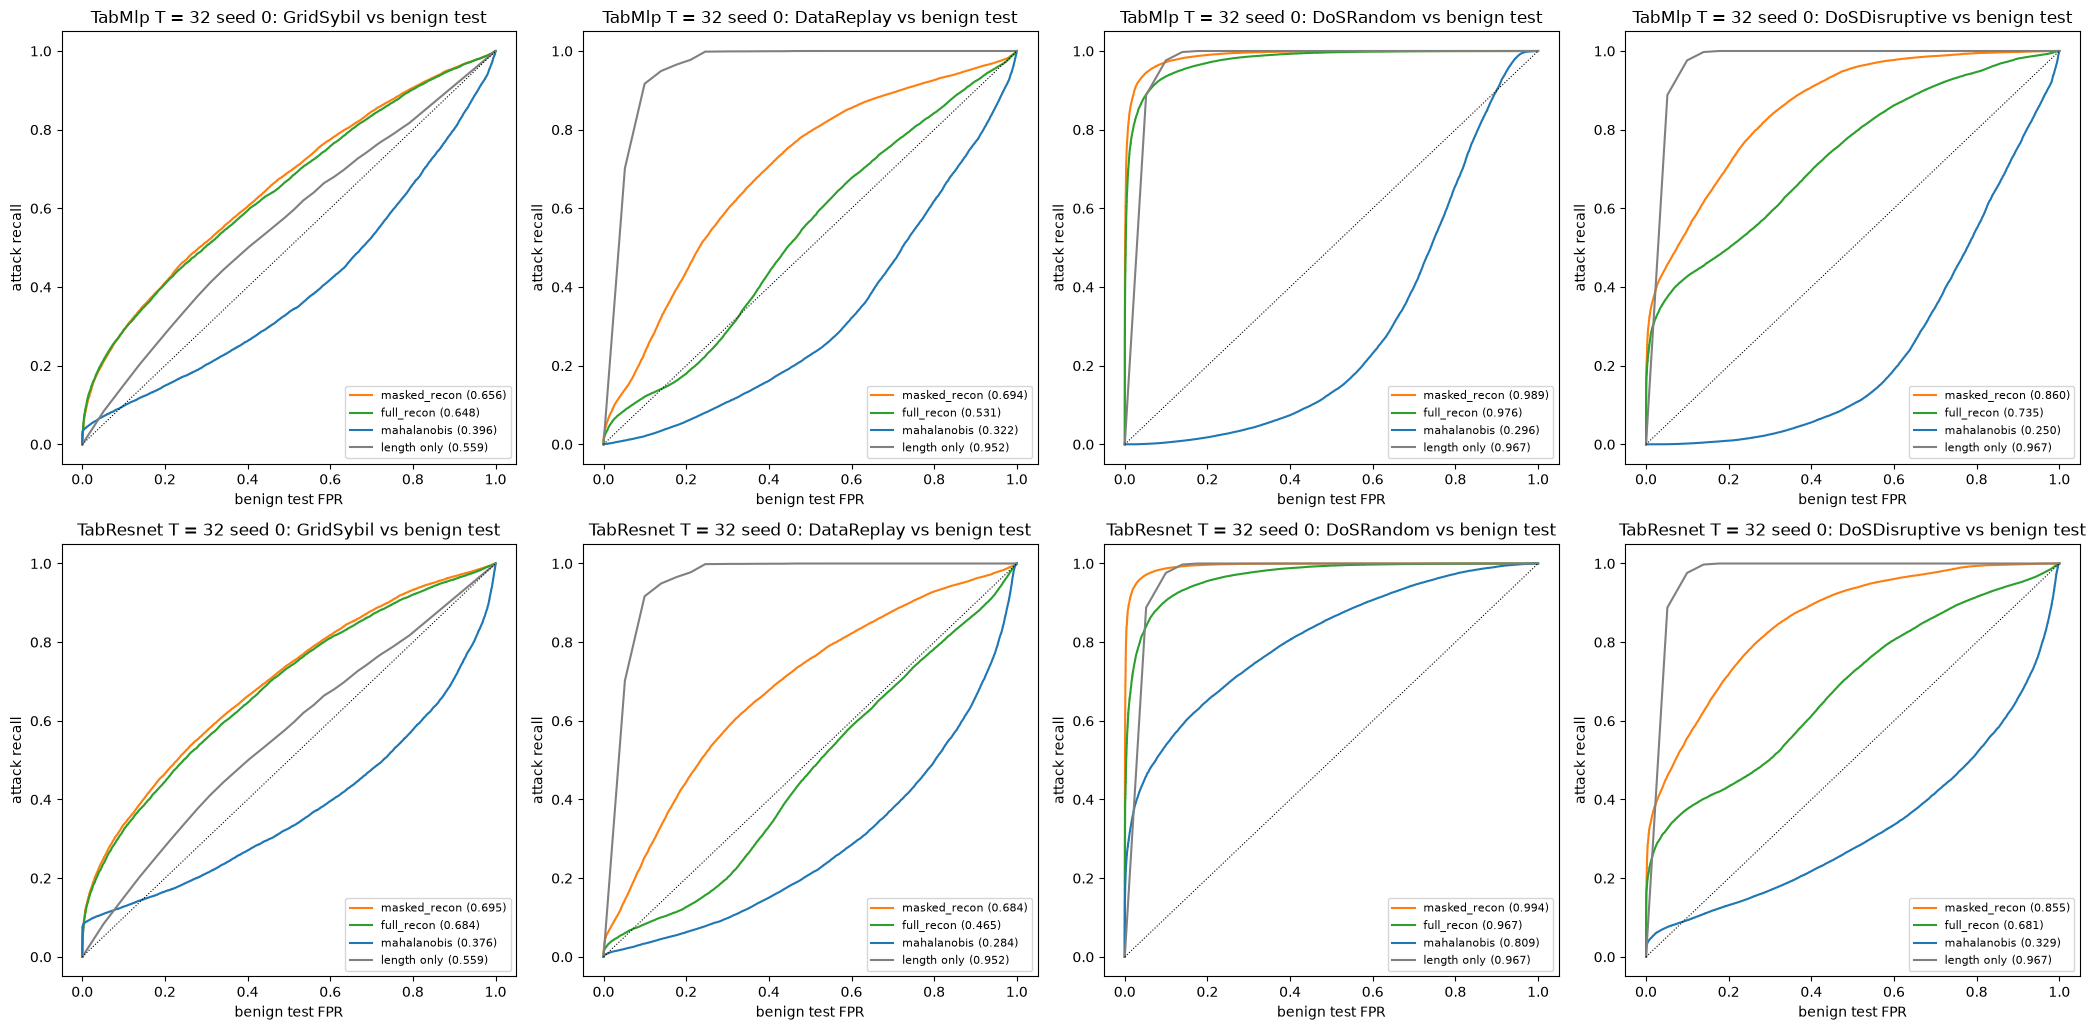

In [18]:
fig, axes = plt.subplots(len(PRESENT), 4, figsize=(21, 5.2 * len(PRESENT)), squeeze=False)
for row, enc in enumerate(PRESENT):
    for ax, attack in zip(axes[row], ATTACKS):
        y, s, n = roc_data(enc, 32, 0, attack)
        for name in SCORE_ORDER:
            v = -n.astype(float) if name == "length only" else s[name]
            fpr, tpr, _ = roc_curve(y, v)
            ax.plot(fpr, tpr, color=colors[name], label=f"{name} ({roc_auc_score(y, v):.3f})")
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set_title(f"{ENCODER_NAMES[enc]} T = 32 seed 0: {attack} vs benign test")
        ax.set_xlabel("benign test FPR")
        ax.set_ylabel("attack recall")
        ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

Score distributions, GridSybil vs benign test, seed 0 per T, with the benign val p95 threshold (one figure per encoder).

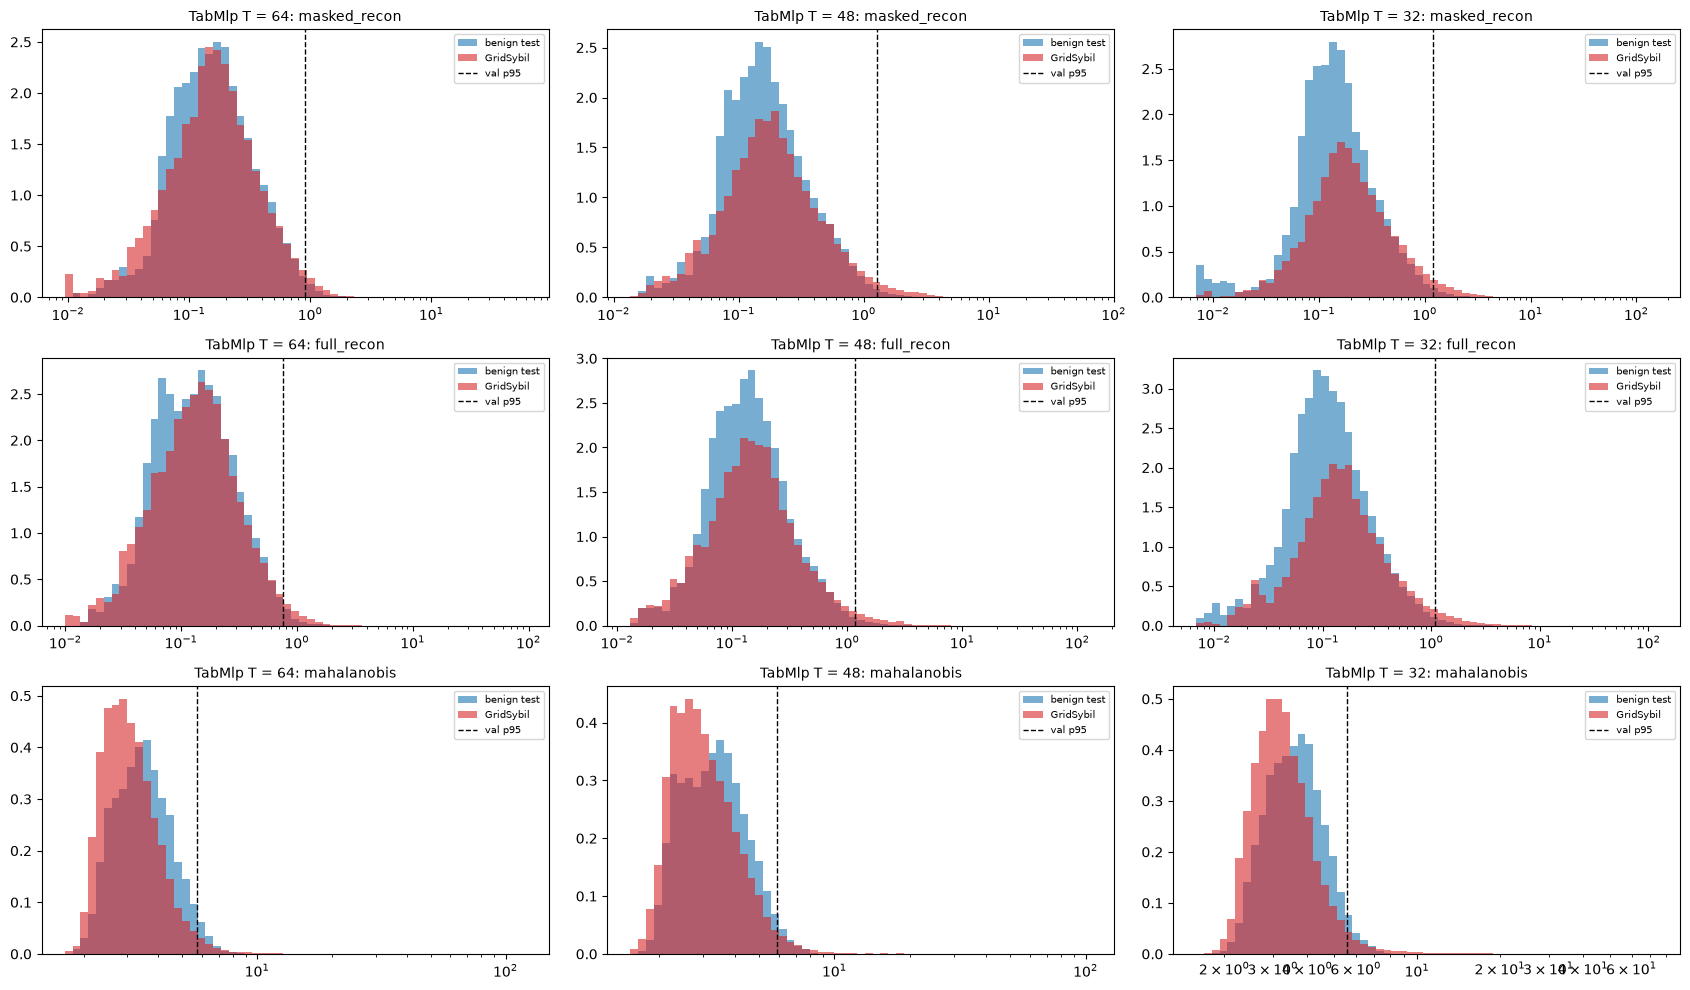

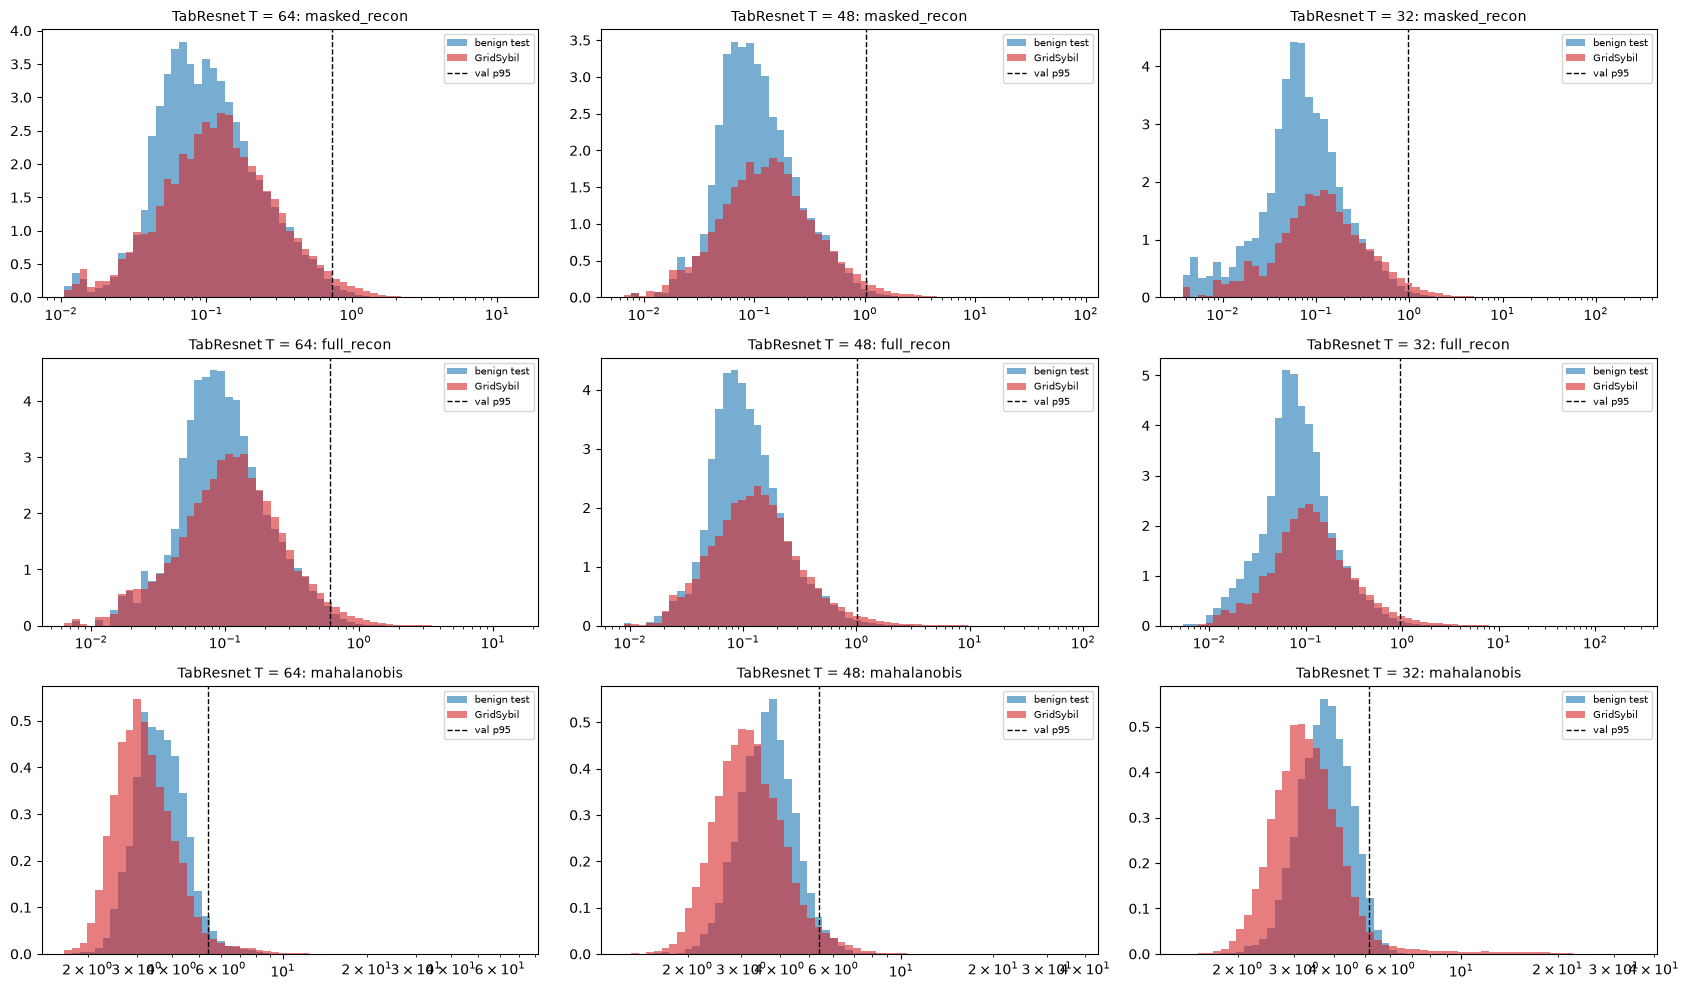

In [19]:
for enc in PRESENT:
    fig, axes = plt.subplots(len(SCORES), len(WINDOWS), figsize=(17, 10))
    for j, t in enumerate(WINDOWS):
        y, s, _ = roc_data(enc, t, 0, "GridSybil")
        thr = RUNS[(enc, t, 0)]["summary"]["thresholds"]["window"]
        for i, name in enumerate(SCORES):
            ax, v = axes[i, j], s[name]
            bins = np.logspace(np.log10(max(v.min(), 1e-4)), np.log10(v.max()), 60)
            ax.hist(v[y == 0], bins=bins, density=True, alpha=0.6, label="benign test")
            ax.hist(v[y == 1], bins=bins, density=True, alpha=0.6, color="tab:red", label="GridSybil")
            ax.axvline(thr[name]["p95"], color="black", ls="--", lw=1, label="val p95")
            ax.set_xscale("log")
            ax.set_title(f"{ENCODER_NAMES[enc]} T = {t}: {name}", fontsize=10)
            ax.legend(fontsize=7)
    fig.tight_layout()
    plt.show()

### 5b. Window length inside the scores

Short windows are harder to reconstruct while hidden: a 1-row window has no time neighbours, so `masked_recon` must
rebuild a hidden cell from the 12 other features of the same message only. Two checks from the score files, on the
**benign test windows alone** (no attack involved): the median score by real rows per window (T = 32 seed 0), and the
AUROC of each score for separating 1–3-row from longer benign windows (mean over seeds). An AUROC well above 0.5 means
the score partly measures window length.

In [20]:
for enc in PRESENT:
    y, s, n = roc_data(enc, 32, 0, "GridSybil")
    ben = y == 0
    med = pd.DataFrame({name: pd.Series(s[name][ben]).groupby(n[ben]).median() for name in SCORES})
    med["benign windows"] = pd.Series(n[ben]).value_counts().sort_index()
    display(med.loc[[1, 2, 3, 4, 8, 16, 32]].round(3).rename_axis(f"real rows ({enc} T32 seed 0, benign test)"))
rows = []
for enc, t, seed in RUNS:
    y, s, n = roc_data(enc, t, seed, "GridSybil")
    ben = y == 0
    short = (n[ben] <= 3).astype(int)
    rows.append({"encoder": enc, "T": t, "seed": seed, **{name: roc_auc_score(short, s[name][ben]) for name in SCORES}})
txt, _, _ = mean_sd(pd.DataFrame(rows), ["encoder", "T"], list(SCORES))
txt.rename_axis(["encoder", "benign test only: AUROC of 1-3 rows vs >= 4 rows"])

,masked_recon,full_recon,mahalanobis,benign windows
"real rows (mlp T32 seed 0, benign test)",,,,
1,0.635,0.292,3.183,3107
2,0.351,0.187,4.062,2869
3,0.315,0.231,4.043,2393
4,0.386,0.299,3.848,2254
8,0.387,0.352,3.865,1874
16,0.277,0.252,3.893,1320
32,0.186,0.174,3.836,12540


,masked_recon,full_recon,mahalanobis,benign windows
"real rows (resnet T32 seed 0, benign test)",,,,
1,0.433,0.123,3.314,3107
2,0.197,0.116,3.496,2869
3,0.211,0.150,3.571,2393
4,0.257,0.203,3.640,2254
8,0.278,0.232,3.693,1874
16,0.193,0.190,3.866,1320
32,0.122,0.128,4.378,12540


masked_recon     full_recon    mahalanobis
encoder benign test only: AUROC of 1-3 rows vs >= 4 rows                                             
mlp     64                                                0.712 ± 0.009  0.545 ± 0.009  0.286 ± 0.026
        48                                                0.698 ± 0.004  0.537 ± 0.007    0.3 ± 0.025
        32                                                0.688 ± 0.004  0.541 ± 0.011  0.413 ± 0.045
resnet  64                                                0.657 ± 0.006  0.381 ± 0.006  0.209 ± 0.049
        48                                                0.659 ± 0.013  0.436 ± 0.011  0.179 ± 0.004
        32                                                 0.63 ± 0.005  0.417 ± 0.011  0.279 ± 0.024

**Length-matched AUROC**: the AUROC is computed separately inside every exact window length (real rows 1, 2, …, T) that
holds both benign and attack windows, and averaged with weights = attack windows at that length. Attack windows can
then no longer be told apart by being shorter than benign ones. `covered` = share of the attack windows whose length
also occurs among the benign test windows. Mean ± sd over seeds, next to the pooled AUROC and length only.

In [21]:
def length_matched_auroc(y, v, n):
    # attack-count-weighted mean of the AUROC within each exact length holding both classes; (auroc, covered share).
    aucs, weights = [], []
    for k in np.unique(n[y == 1]):
        sel = n == k
        if 0 < y[sel].sum() < sel.sum():
            aucs.append(roc_auc_score(y[sel], v[sel]))
            weights.append(y[sel].sum())
    return float(np.average(aucs, weights=weights)), float(np.sum(weights) / (y == 1).sum())


rows = []
for (enc, t, seed), r in RUNS.items():
    for attack in r["test_metrics"]["attacks"]:
        y, s, n = roc_data(enc, t, seed, attack)
        for name in SCORES:
            lm, cov = length_matched_auroc(y, s[name], n)
            rows.append(
                {
                    "encoder": enc,
                    "T": t,
                    "seed": seed,
                    "attack": attack,
                    "score": name,
                    "pooled AUROC": roc_auc_score(y, s[name]),
                    "length-matched AUROC": lm,
                    "covered": cov,
                }
            )
lm = pd.DataFrame(rows)
lm["case"] = "T" + lm["T"].astype(str) + " " + lm["attack"]
txt, mu_lm, sd_lm = mean_sd(lm, ["encoder", "case", "score"], ["pooled AUROC", "length-matched AUROC", "covered"])
length_only = res[res.score == "length only"].assign(case=lambda d: "T" + d["T"].astype(str) + " " + d["attack"])
txt = txt.join(
    length_only.groupby(["encoder", "case"]).AUROC.mean().round(3).rename("length only"), on=["encoder", "case"]
)
txt

pooled AUROC length-matched AUROC    covered  length only
encoder case              score                                                                   
mlp     T64 GridSybil     masked_recon  0.531 ± 0.002         0.51 ± 0.002  1.0 ± 0.0        0.535
                          full_recon    0.539 ± 0.003         0.53 ± 0.003  1.0 ± 0.0        0.535
                          mahalanobis   0.398 ± 0.018        0.403 ± 0.019  1.0 ± 0.0        0.535
        T48 GridSybil     masked_recon  0.607 ± 0.001        0.589 ± 0.001  1.0 ± 0.0        0.530
                          full_recon    0.603 ± 0.002        0.595 ± 0.002  1.0 ± 0.0        0.530
                          mahalanobis   0.403 ± 0.016        0.408 ± 0.019  1.0 ± 0.0        0.530
        T32 GridSybil     masked_recon  0.657 ± 0.002        0.631 ± 0.001  1.0 ± 0.0        0.559
                          full_recon     0.65 ± 0.003        0.638 ± 0.003  1.0 ± 0.0        0.559
                          mahalanobis   0.408 ± 0.017        0.415 ± 0.019  1.0 ± 0.0        0.559
        T32 DataReplay    masked_recon  0.693 ± 0.003         0.49 ± 0.009  1.0 ± 0.0        0.952
                          full_recon      0.54 ± 0.01        0.491 ± 0.011  1.0 ± 0.0        0.952
                          mahalanobis   0.269 ± 0.036         0.437 ± 0.03  1.0 ± 0.0        0.952
        T32 DoSRandom     masked_recon  0.988 ± 0.001         0.97 ± 0.001  1.0 ± 0.0        0.967
                          full_recon    0.976 ± 0.002        0.971 ± 0.002  1.0 ± 0.0        0.967
                          mahalanobis   0.394 ± 0.073        0.656 ± 0.118  1.0 ± 0.0        0.967
        T32 DoSDisruptive masked_recon  0.851 ± 0.006        0.679 ± 0.005  1.0 ± 0.0        0.967
                          full_recon    0.732 ± 0.007        0.683 ± 0.003  1.0 ± 0.0        0.967
                          mahalanobis   0.222 ± 0.032         0.447 ± 0.07  1.0 ± 0.0        0.967
resnet  T64 GridSybil     masked_recon  0.595 ± 0.003        0.578 ± 0.004  1.0 ± 0.0        0.535
                          full_recon    0.605 ± 0.003        0.609 ± 0.003  1.0 ± 0.0        0.535
                          mahalanobis   0.368 ± 0.009        0.347 ± 0.012  1.0 ± 0.0        0.535
        T48 GridSybil     masked_recon   0.65 ± 0.002         0.64 ± 0.002  1.0 ± 0.0        0.530
                          full_recon    0.648 ± 0.001         0.65 ± 0.001  1.0 ± 0.0        0.530
                          mahalanobis   0.381 ± 0.007        0.366 ± 0.006  1.0 ± 0.0        0.530
        T32 GridSybil     masked_recon  0.696 ± 0.001        0.678 ± 0.001  1.0 ± 0.0        0.559
                          full_recon    0.685 ± 0.002        0.688 ± 0.004  1.0 ± 0.0        0.559
                          mahalanobis   0.378 ± 0.004        0.387 ± 0.003  1.0 ± 0.0        0.559
        T32 DataReplay    masked_recon  0.695 ± 0.008        0.559 ± 0.007  1.0 ± 0.0        0.952
                          full_recon     0.46 ± 0.011        0.579 ± 0.006  1.0 ± 0.0        0.952
                          mahalanobis   0.271 ± 0.023        0.474 ± 0.023  1.0 ± 0.0        0.952
        T32 DoSRandom     masked_recon    0.994 ± 0.0          0.988 ± 0.0  1.0 ± 0.0        0.967
                          full_recon    0.964 ± 0.002        0.985 ± 0.002  1.0 ± 0.0        0.967
                          mahalanobis   0.629 ± 0.165        0.827 ± 0.089  1.0 ± 0.0        0.967
        T32 DoSDisruptive masked_recon  0.859 ± 0.004        0.734 ± 0.001  1.0 ± 0.0        0.967
                          full_recon    0.672 ± 0.009         0.77 ± 0.007  1.0 ± 0.0        0.967
                          mahalanobis   0.281 ± 0.033        0.488 ± 0.031  1.0 ± 0.0        0.967

In [22]:
y, s, n = roc_data(PRESENT[0], 32, 0, "DataReplay")
print(
    f"T32 seed 0: 1-row windows {np.mean(n[y == 1] == 1):.1%} of DataReplay vs {np.mean(n[y == 0] == 1):.1%} of benign test"
)

T32 seed 0: 1-row windows 70.2% of DataReplay vs 5.2% of benign test


## 6. Comparison with the one-class ConvAE

Same windows, same splits, same thresholds rule: the one-class ConvAE cells (`task/encoder` ae at T = 64,
`task/autoencoder_benign_t48`, `task/autoencoder_benign_t32`), seeds 0–3, mean ± sample sd, quoted from
`baselinepaper/01-our-studies/inventory.md` ("Four seeds per cell"; the only hard-coded numbers in this notebook). The
ConvAE's reconstruction score is the masked MSE over real rows with nothing hidden, i.e. the counterpart of
`full_recon`; `masked_recon` is the masked-autoencoder's own score. Differences: model family and size, loss (hidden
cells only), and at T = 64 the ConvAE's Mahalanobis used a ridge of 1e-6 instead of shrinkage. Four seeds per side, no
test of significance.

One row block per encoder present.

In [23]:
CONVAE = {  # inventory.md, seeds 0-3, window AUROC mean ± sample sd
    (64, "GridSybil"): {"recon": (0.657, 0.004), "mahalanobis": (0.322, 0.015)},
    (48, "GridSybil"): {"recon": (0.682, 0.006), "mahalanobis": (0.446, 0.015)},
    (32, "GridSybil"): {"recon": (0.734, 0.003), "mahalanobis": (0.505, 0.012)},
    (32, "DataReplay"): {"recon": (0.387, 0.010)},
    (32, "DoSRandom"): {"recon": (0.967, 0.005)},
    (32, "DoSDisruptive"): {"recon": (0.598, 0.012)},
}
_, mu_all, sd_all = mean_sd(res, ["encoder", "T", "attack", "score"], ["AUROC"])
fmt = lambda m, s: f"{m:.3f} ± {s:.3f}"
comp = []
for enc in PRESENT:
    for (t, attack), c in CONVAE.items():
        g = lambda name: (mu_all.loc[(enc, t, attack, name), "AUROC"], sd_all.loc[(enc, t, attack, name), "AUROC"])
        comp.append(
            {
                "encoder": enc,
                "T": t,
                "attack": attack,
                "MAE masked_recon": fmt(*g("masked_recon")),
                "MAE full_recon": fmt(*g("full_recon")),
                "ConvAE recon": fmt(*c["recon"]),
                "masked_recon - ConvAE": round(g("masked_recon")[0] - c["recon"][0], 3),
                "full_recon - ConvAE": round(g("full_recon")[0] - c["recon"][0], 3),
                "MAE mahalanobis": fmt(*g("mahalanobis")),
                "ConvAE mahalanobis": fmt(*c["mahalanobis"]) if "mahalanobis" in c else "-",
                "length only": round(mu_all.loc[(enc, t, attack, "length only"), "AUROC"], 3),
            }
        )
comp = pd.DataFrame(comp).set_index(["encoder", "T", "attack"])
comp

MAE masked_recon MAE full_recon   ConvAE recon  masked_recon - ConvAE  full_recon - ConvAE MAE mahalanobis ConvAE mahalanobis  length only
encoder T  attack                                                                                                                                                  
mlp     64 GridSybil        0.531 ± 0.002  0.539 ± 0.003  0.657 ± 0.004                 -0.126               -0.118   0.398 ± 0.018      0.322 ± 0.015        0.535
        48 GridSybil        0.607 ± 0.001  0.603 ± 0.002  0.682 ± 0.006                 -0.075               -0.079   0.403 ± 0.016      0.446 ± 0.015        0.530
        32 GridSybil        0.657 ± 0.002  0.650 ± 0.003  0.734 ± 0.003                 -0.077               -0.084   0.408 ± 0.017      0.505 ± 0.012        0.559
           DataReplay       0.693 ± 0.003  0.540 ± 0.010  0.387 ± 0.010                  0.306                0.153   0.269 ± 0.036                  -        0.952
           DoSRandom        0.988 ± 0.001  0.976 ± 0.002  0.967 ± 0.005                  0.021                0.009   0.394 ± 0.073                  -        0.967
           DoSDisruptive    0.851 ± 0.006  0.732 ± 0.007  0.598 ± 0.012                  0.253                0.134   0.222 ± 0.032                  -        0.967
resnet  64 GridSybil        0.595 ± 0.003  0.605 ± 0.003  0.657 ± 0.004                 -0.062               -0.052   0.368 ± 0.009      0.322 ± 0.015        0.535
        48 GridSybil        0.650 ± 0.002  0.648 ± 0.001  0.682 ± 0.006                 -0.032               -0.034   0.381 ± 0.007      0.446 ± 0.015        0.530
        32 GridSybil        0.696 ± 0.001  0.685 ± 0.002  0.734 ± 0.003                 -0.038               -0.049   0.378 ± 0.004      0.505 ± 0.012        0.559
           DataReplay       0.695 ± 0.008  0.460 ± 0.011  0.387 ± 0.010                  0.308                0.073   0.271 ± 0.023                  -        0.952
           DoSRandom        0.994 ± 0.000  0.964 ± 0.002  0.967 ± 0.005                  0.027               -0.003   0.629 ± 0.165                  -        0.967
           DoSDisruptive    0.859 ± 0.004  0.672 ± 0.009  0.598 ± 0.012                  0.261                0.074   0.281 ± 0.033                  -        0.967

## 7. TabMlp vs TabResnet

The two encoders on the same windows, splits, masks and thresholds rule, per T and attack (the GridSybil cases at every
T, the four attacks at T = 32). Five window-AUROC views, each mean ± sample sd over seeds 0–3: **pooled** masked_recon
and full_recon, **length-matched** masked_recon (section 5b), masked_recon on **≥ 4-row** windows only, and
**Mahalanobis** on z. `resnet - mlp` = difference of the means (four seeds per side, no significance test). With only
one encoder on disk the table shows that encoder alone and the difference column is left out.

In [24]:
VIEWS = {  # view -> (frame, score, column)
    "pooled masked_recon": (res, "masked_recon", "AUROC"),
    "pooled full_recon": (res, "full_recon", "AUROC"),
    "length-matched masked_recon": (lm, "masked_recon", "length-matched AUROC"),
    ">= 4 rows masked_recon": (res, "masked_recon", "AUROC >= 4 rows"),
    "mahalanobis": (res, "mahalanobis", "AUROC"),
}
CASES = [f"T{t} GridSybil" for t in WINDOWS] + [f"T32 {a}" for a in ATTACKS[1:]]
long = []
for view, (frame, score, col) in VIEWS.items():
    f = frame[frame.score == score].assign(case=lambda d: "T" + d["T"].astype(str) + " " + d["attack"])
    f = f[f.case.isin(CASES)]
    long.append(f[["encoder", "case", "seed"]].assign(view=view, value=f[col].to_numpy()))
long = pd.concat(long, ignore_index=True)
g = long.groupby(["case", "view", "encoder"], sort=False)["value"]
assert (g.size() == len(SEEDS)).all()
mu, sd = g.mean().unstack("encoder"), g.std(ddof=1).unstack("encoder")
enc_cmp = pd.DataFrame(index=pd.MultiIndex.from_product([CASES, list(VIEWS)], names=["case", "view"]))
for enc in PRESENT:
    enc_cmp[ENCODER_NAMES[enc]] = (mu[enc].round(3).astype(str) + " ± " + sd[enc].round(3).astype(str)).reindex(
        enc_cmp.index
    )
if {"mlp", "resnet"} <= set(PRESENT):
    enc_cmp["resnet - mlp"] = (mu["resnet"] - mu["mlp"]).round(3).reindex(enc_cmp.index)
else:
    print(
        f"only {PRESENT} on disk: the comparison shows it alone; rerun after `npm run mae:all:resnet` "
        "(or `npm run hf:download:baselines:mae:resnet`)"
    )
enc_cmp

TabMlp      TabResnet  resnet - mlp
case              view                                                                   
T64 GridSybil     pooled masked_recon          0.531 ± 0.002  0.595 ± 0.003         0.064
                  pooled full_recon            0.539 ± 0.003  0.605 ± 0.003         0.066
                  length-matched masked_recon   0.51 ± 0.002  0.578 ± 0.004         0.068
                  >= 4 rows masked_recon        0.55 ± 0.002  0.604 ± 0.003         0.054
                  mahalanobis                  0.398 ± 0.018  0.368 ± 0.009        -0.030
T48 GridSybil     pooled masked_recon          0.607 ± 0.001   0.65 ± 0.002         0.043
                  pooled full_recon            0.603 ± 0.002  0.648 ± 0.001         0.045
                  length-matched masked_recon  0.589 ± 0.001   0.64 ± 0.002         0.050
                  >= 4 rows masked_recon       0.619 ± 0.001  0.654 ± 0.001         0.034
                  mahalanobis                  0.403 ± 0.016  0.381 ± 0.007        -0.022
T32 GridSybil     pooled masked_recon          0.657 ± 0.002  0.696 ± 0.001         0.040
                  pooled full_recon             0.65 ± 0.003  0.685 ± 0.002         0.035
                  length-matched masked_recon  0.631 ± 0.001  0.678 ± 0.001         0.048
                  >= 4 rows masked_recon       0.674 ± 0.002  0.706 ± 0.001         0.032
                  mahalanobis                  0.408 ± 0.017  0.378 ± 0.004        -0.030
T32 DataReplay    pooled masked_recon          0.693 ± 0.003  0.695 ± 0.008         0.003
                  pooled full_recon              0.54 ± 0.01   0.46 ± 0.011        -0.079
                  length-matched masked_recon   0.49 ± 0.009  0.559 ± 0.007         0.069
                  >= 4 rows masked_recon       0.359 ± 0.004  0.375 ± 0.012         0.016
                  mahalanobis                  0.269 ± 0.036  0.271 ± 0.023         0.002
T32 DoSRandom     pooled masked_recon          0.988 ± 0.001    0.994 ± 0.0         0.006
                  pooled full_recon            0.976 ± 0.002  0.964 ± 0.002        -0.012
                  length-matched masked_recon   0.97 ± 0.001    0.988 ± 0.0         0.018
                  >= 4 rows masked_recon           1.0 ± 0.0      1.0 ± 0.0        -0.000
                  mahalanobis                  0.394 ± 0.073  0.629 ± 0.165         0.235
T32 DoSDisruptive pooled masked_recon          0.851 ± 0.006  0.859 ± 0.004         0.008
                  pooled full_recon            0.732 ± 0.007  0.672 ± 0.009        -0.061
                  length-matched masked_recon  0.679 ± 0.005  0.734 ± 0.001         0.055
                  >= 4 rows masked_recon           1.0 ± 0.0      1.0 ± 0.0        -0.000
                  mahalanobis                  0.222 ± 0.032  0.281 ± 0.033         0.059

The same five views as points with ± 1 sd error bars (one panel per view, one marker per encoder; the dotted line is
chance).

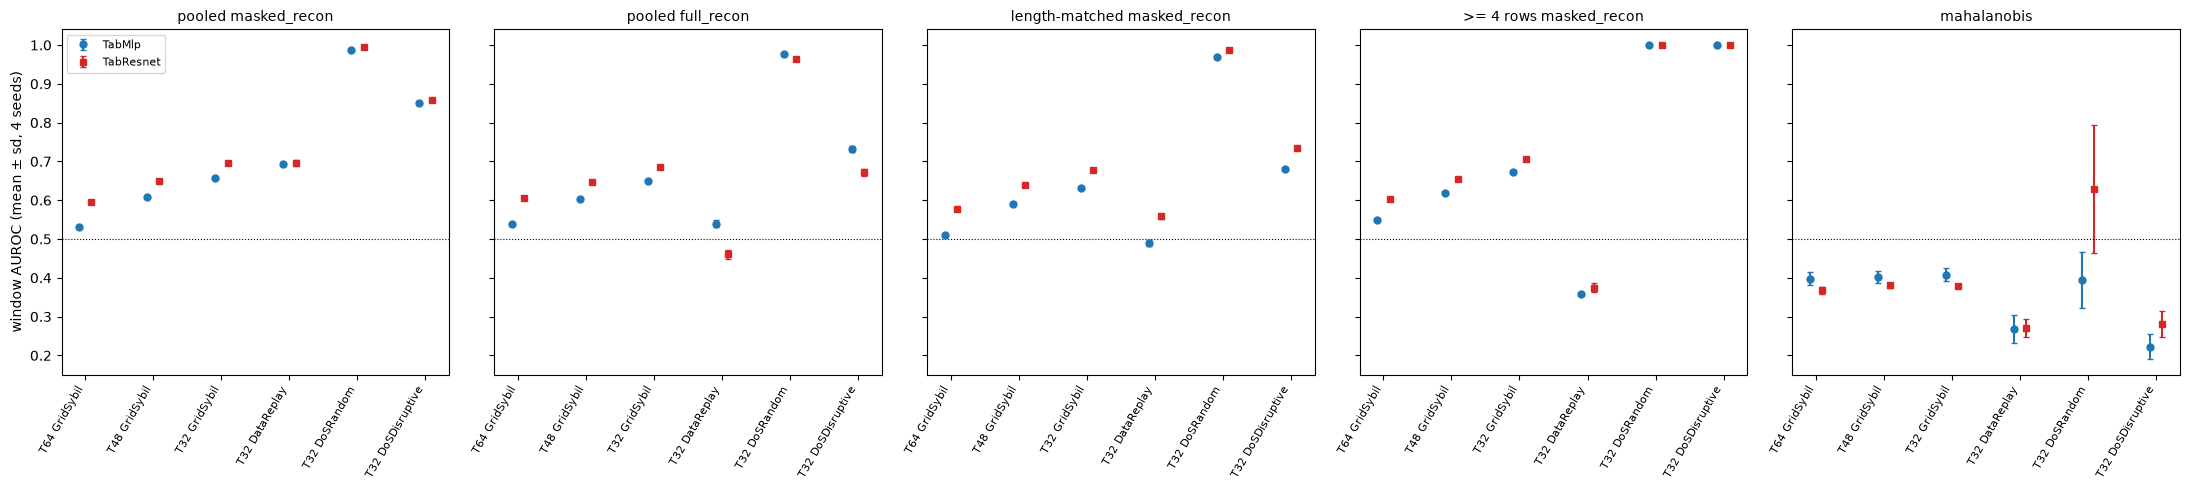

In [25]:
markers = {"mlp": ("o", "tab:blue"), "resnet": ("s", "tab:red")}
fig, axes = plt.subplots(1, len(VIEWS), figsize=(4.4 * len(VIEWS), 5), sharey=True)
x = np.arange(len(CASES))
for ax, view in zip(axes, VIEWS):
    for k, enc in enumerate(PRESENT):
        m = mu.xs(view, level="view")[enc].reindex(CASES)
        e = sd.xs(view, level="view")[enc].reindex(CASES)
        off = (k - (len(PRESENT) - 1) / 2) * 0.18
        mk, col = markers[enc]
        ax.errorbar(x + off, m.values, yerr=e.values, fmt=mk, color=col, ms=5, capsize=2, label=ENCODER_NAMES[enc])
    ax.axhline(0.5, color="k", ls=":", lw=0.8)
    ax.set_xticks(x, CASES, rotation=60, ha="right", fontsize=8)
    ax.set_title(view, fontsize=10)
axes[0].set_ylabel("window AUROC (mean ± sd, 4 seeds)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

The numbers the analysis below refers to.

In [26]:
summary_numbers = {}
for enc in PRESENT:
    gs = gs_table.xs(enc, level=0)
    t32e = t32_table.xs(enc, level=0)
    r, sh = rec.xs(enc, level="encoder"), shape.xs(enc, level="encoder")
    summary_numbers[enc] = {
        "GridSybil window AUROC (mean ± sd, seeds 0-3)": gs.to_dict(),
        "T32 window AUROC": t32e.to_dict(),
        "best epochs": r["best epoch"].groupby(level=0).agg(list).to_dict(),
        "train minutes": r["train min"].groupby(level=0).agg(list).to_dict(),
        "val masked (best), mean": r["val masked (best)"].groupby(level=0).mean().round(4).to_dict(),
        "val full / masked at best, mean": sh["val full / val masked at best"]
        .groupby(level=0)
        .mean()
        .round(3)
        .to_dict(),
        "share of val decrease by epoch 10, mean": sh["share of decrease by epoch 10"]
        .groupby(level=0)
        .mean()
        .round(3)
        .to_dict(),
        "length-matched AUROC, masked_recon": mu_lm.xs((enc, "masked_recon"), level=["encoder", "score"])[
            "length-matched AUROC"
        ]
        .round(3)
        .to_dict(),
    }
summary_numbers

{'mlp': {'GridSybil window AUROC (mean ± sd, seeds 0-3)': {'T = 64': {'masked_recon': '0.531 ± 0.002',
    'full_recon': '0.539 ± 0.003',
    'mahalanobis': '0.398 ± 0.018',
    'length only': '0.535 ± 0.0'},
   'T = 48': {'masked_recon': '0.607 ± 0.001',
    'full_recon': '0.603 ± 0.002',
    'mahalanobis': '0.403 ± 0.016',
    'length only': '0.53 ± 0.0'},
   'T = 32': {'masked_recon': '0.657 ± 0.002',
    'full_recon': '0.65 ± 0.003',
    'mahalanobis': '0.408 ± 0.017',
    'length only': '0.559 ± 0.0'}},
  'T32 window AUROC': {'GridSybil': {'masked_recon': '0.657 ± 0.002',
    'full_recon': '0.65 ± 0.003',
    'mahalanobis': '0.408 ± 0.017',
    'length only': '0.559 ± 0.0'},
   'DataReplay': {'masked_recon': '0.693 ± 0.003',
    'full_recon': '0.54 ± 0.01',
    'mahalanobis': '0.269 ± 0.036',
    'length only': '0.952 ± 0.0'},
   'DoSRandom': {'masked_recon': '0.988 ± 0.001',
    'full_recon': '0.976 ± 0.002',
    'mahalanobis': '0.394 ± 0.073',
    'length only': '0.967 ± 0.0'},


## 8. Analysis

### TabMlp (`mlp`)

Numbers from the outputs above (12 runs, TabMlp, seeds 0–3, mean ± sample sd, n = 4). One-class: the training and
validation windows are benign windows selected with labels; no label enters the loss. Side experiment, not a thesis
detection result (RULE 1: reported as produced).

- **Training converged quickly and stopped by early stopping in all 12 runs.** 113,616 / 85,760 / 57,904 parameters at
  T = 64 / 48 / 32. 68–85 % of the val masked-MSE decrease (epoch 1 → best) was reached by epoch 10 (mean 0.83 / 0.76 /
  0.74); after the first LR halving the val loss improved by only 1–3 % more. Best epochs 41–68 (T64), 80–110 (T48),
  43–58 (T32); 0.7–5.4 min per run on MPS. Best val masked MSE 0.292 / 0.346 / 0.324; the val full-reconstruction MSE is
  4–7 % lower than the masked one. No dead z units, Mahalanobis condition numbers 56–1,229 (no shrinkage needed).
- **The blue curve sits above the val curves (train / val 1.45–1.76 at the best epoch) by construction, not from
  under-fitting or leakage.** Training minimises widedeep's variance-normalised `EncoderDecoderLoss` (hidden cells only,
  per-window mean, dropout on); early stopping, the LR schedule and all three test scores use the plain MSE on the
  z-scored features (pooled over cells, dropout off). Both fall together over the epochs; their gap is not a
  generalisation gap.
- **GridSybil: weak and below the one-class ConvAE at every T.** Window AUROC masked_recon 0.531 ± 0.002 / 0.607 ±
  0.001 / 0.657 ± 0.002 at T = 64 / 48 / 32 (full_recon 0.539 / 0.603 / 0.650; length only 0.535 / 0.530 / 0.559),
  vs the ConvAE's 0.657 / 0.682 / 0.734 on the same windows: 0.08–0.13 lower. At T = 64 it is at the length-only level.
  Recall at val p95 0.09 / 0.17 / 0.21 at a benign test FPR of 0.045–0.052; per track it does not improve. Seed spread is
  small (sd ≤ 0.003) for the reconstruction scores.
- **Mahalanobis on z is below chance everywhere** (GridSybil 0.398–0.408; T32 DataReplay 0.269, DoSRandom 0.394 ± 0.073,
  DoSDisruptive 0.222): attack windows sit closer to the benign z mean than benign test windows do. It is also the least
  stable score across seeds.
- **The masked-reconstruction score partly measures window length.** A 1-row window has no time neighbours, so a hidden
  cell must be rebuilt from the same message alone: on benign test windows the median masked_recon is 0.635 for 1 row vs
  0.186 for 32 rows (T32 seed 0), and masked_recon alone separates 1–3-row from longer **benign** windows with AUROC
  0.712 / 0.698 / 0.688 (full_recon 0.545 / 0.537 / 0.541).
- **Length-matched AUROC** (within each exact length, weighted by attack windows): GridSybil 0.510 / 0.589 / 0.631
  (masked_recon), so most of the GridSybil signal is not length; T32 DataReplay **0.490** (chance), DoSRandom 0.970,
  DoSDisruptive 0.679 (pooled 0.851). The pooled T32 DataReplay AUROC 0.693 comes from length (70.2 % of DataReplay
  windows have 1 row vs 5.2 % of benign test windows) and **must not be reported as detection**; it is also far below
  length only (0.952). The DataReplay / DoSDisruptive gains over the ConvAE in section 6 are the same length effect.
- **DoS:** DoSRandom masked_recon 0.988 pooled and 0.970 length-matched, above length only (0.967) by 0.02 or less.
  The ≥ 4-row AUROC of 1.000 for both DoS attacks rests on only 523 / 524 attack windows (vs 51,773 benign), so it is a
  small-sample figure.
- **Reading.** Under this protocol the widedeep-style flattened-window masked autoencoder is a weaker one-class
  GridSybil detector than the ConvAE at every T (four seeds each side, no significance test), and its higher pooled
  numbers on DataReplay / DoSDisruptive are a window-length artefact. The ranking T32 > T48 > T64 matches the ConvAE's,
  but the T = 32 and T = 48 / 64 test sets differ (all 8 folders vs benign + GridSybil folders, attack share 0.32 vs
  0.67), so the T trend is not a clean window-size effect.

### TabResnet (`resnet`)

**Pending**: the 12 TabResnet runs (`npm run mae:all:resnet`) are not on disk yet. When they are, sections 1–7 include
them automatically; this analysis and section 7's reading are written after the runs, from the outputs above.